# BT4012 Kaggle Competition (A0291981R)
Selected submission on Kaggle: iian submission 41.csv
- Public score: 0.96130
- Private score: 0.95073

1. **Part 1: Data Preprocessing.** Loads and validates the raw CSVs, builds the transaction graph and the feature matrices.
2. **Part 2: Feature Engineering.** Tests candidate feature blocks on time-based folds and saves the final feature set.
3. **Part 3: Model Training, Prediction, and Validation.** Compares models and writes the submission, a rank blend of LightGBM (0.6) and a two-layer GraphSAGE GNN (0.4).

Place it in the project root, next to the `data/` folder that holds the raw CSVs.

## Import Libraries

In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.stats import binomtest, rankdata, ttest_rel

import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False

try:
    import optuna
    HAS_OPTUNA = True
except ImportError:
    HAS_OPTUNA = False

# Part 1: Data Preprocessing

Loads the raw CSVs, validates them, builds the transaction graph and node-aligned feature matrices, and saves everything to `data/processed` for the feature engineering and prediction parts.

Findings that shape the whole pipeline: labels are scarce and imbalanced, each time step is its own graph component (no edge links two steps), and test steps have far fewer nodes with features than training steps.

## 1. Import Libraries

The imports for this part are in the import cell at the top of the notebook.

## 2. User Configuration

In [ ]:
# Paths and constants
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
SUBMISSION_DIR = PROJECT_ROOT / "submissions"

# Column names used throughout. The first 93 features describe the transaction itself
# (local); the other 72 summarise its one-hop neighbours (aggregated)
ID, STEP, TARGET = "txId", "time_step", "label"
LOCAL_FEATURE_COUNT = 93

# Degree cut-offs for the diagnostic in section 10, and the minimum rows a time step
# needs before its features are ranked (section 11)
LOW_DEGREE, HIGH_DEGREE = 1, 5
MIN_STEP_ROWS = 30

# Create the output folders if they do not exist
for directory in (PROCESSED_DIR, MODEL_DIR, SUBMISSION_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"Processed    : {PROCESSED_DIR}")
print(f"Model        : {MODEL_DIR}")
print(f"Submission   : {SUBMISSION_DIR}")

Project root : c:\Users\iiank-laptop\OneDrive\Documents\NUS\Y3\Y3S1\BT4012\Kaggle
Processed    : c:\Users\iiank-laptop\OneDrive\Documents\NUS\Y3\Y3S1\BT4012\Kaggle\data\processed
Model        : c:\Users\iiank-laptop\OneDrive\Documents\NUS\Y3\Y3S1\BT4012\Kaggle\models
Submission   : c:\Users\iiank-laptop\OneDrive\Documents\NUS\Y3\Y3S1\BT4012\Kaggle\submissions


## 3. Loading Data

In [ ]:
# Load the raw csv files. Features are read as float32 to halve memory
header = pd.read_csv(DATA_DIR / "train.csv", nrows=0).columns
FEATURE_COLUMNS = [c for c in header if c.startswith("feat_")]
N_FEATURES = len(FEATURE_COLUMNS)

dtypes = {c: np.float32 for c in FEATURE_COLUMNS}
dtypes.update({ID: np.int64, STEP: np.int16})

train_raw = pd.read_csv(DATA_DIR / "train.csv", dtype=dtypes)
test_raw = pd.read_csv(DATA_DIR / "test.csv", dtype=dtypes)
edges_raw = pd.read_csv(DATA_DIR / "txs_edgelist.csv", dtype={"txId1": np.int64, "txId2": np.int64})
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print(f"features         : {N_FEATURES}")
print(f"train            : {train_raw.shape}")
print(f"test             : {test_raw.shape}")
print(f"edges            : {edges_raw.shape}")
print(f"sample_submission: {sample_submission.shape}")

features         : 165
train            : (141772, 168)
test             : (15329, 168)
edges            : (234355, 2)
sample_submission: (15329, 2)


## 4. Schema Validation

In [ ]:
# Sanity checks before any processing: transaction IDs must be unique within and across
# splits, and the sample submission must follow the test row order exactly
overlap = len(set(train_raw[ID]) & set(test_raw[ID]))
dup_train = int(train_raw[ID].duplicated().sum())
dup_test = int(test_raw[ID].duplicated().sum())
index_aligned = bool((sample_submission["index"].values == test_raw["index"].values).all())

assert dup_train == 0 and dup_test == 0 and overlap == 0, "txId is not unique across splits"
assert index_aligned, "sample_submission index does not match test index"

print(f"Duplicate txId         : train={dup_train}, test={dup_test}, overlap={overlap}")
print(f"Duplicate edges        : {int(edges_raw.duplicated().sum())}")
print(f"Self-loop edges        : {int((edges_raw['txId1'] == edges_raw['txId2']).sum())}")
print(f"Missing feature values : train={int(train_raw[FEATURE_COLUMNS].isna().sum().sum())}, "
      f"test={int(test_raw[FEATURE_COLUMNS].isna().sum().sum())}")
print(f"Test index contiguous  : {bool((test_raw['index'].values == np.arange(len(test_raw))).all())}")

Duplicate txId         : train=0, test=0, overlap=0
Duplicate edges        : 0
Self-loop edges        : 0
Missing feature values : train=0, test=0
Test index contiguous  : True


## 5. Checking for class imbalance

label
0.0     27591
1.0      3644
NaN    110537
Name: count, dtype: int64


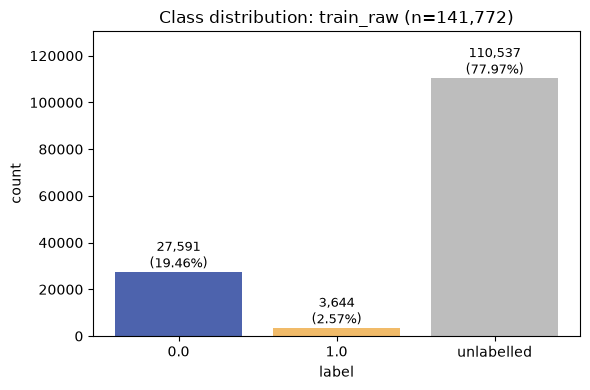

labelled rows    31,235 (22.03% of train)
imbalance ratio  7.57 : 1


In [ ]:
# Label distribution in train.csv
counts = train_raw[TARGET].value_counts(dropna=False).sort_index(na_position="last")
labels = [("unlabelled" if pd.isna(i) else str(i)) for i in counts.index]
pct = counts / len(train_raw) * 100

print(counts)

_, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=["#4d63ad", "#f1bb69", "#bdbdbd"][:len(counts)])
for b, c, p in zip(bars, counts, pct):
    ax.annotate(f"{c:,}\n({p:.2f}%)", (b.get_x() + b.get_width() / 2, c),
                ha="center", va="bottom", fontsize=9)

ax.set_title(f"Class distribution: train_raw (n={len(train_raw):,})")
ax.set_xlabel(TARGET)
ax.set_ylabel("count")
ax.margins(y=0.18)
plt.tight_layout()
plt.show()

# Imbalance among labelled rows only
labelled_counts = counts.loc[[0, 1]]
print(f"labelled rows    {labelled_counts.sum():,} "
      f"({labelled_counts.sum() / len(train_raw) * 100:.2f}% of train)")
print(f"imbalance ratio  {labelled_counts.max() / labelled_counts.min():.2f} : 1")

## 6. Checking time-series split

In [ ]:
# Confirm the temporal design: train covers steps 1-35 and test steps 36-49 with no gaps
for name, frame in [("train", train_raw), ("test", test_raw)]:
    steps = frame[STEP]
    present = sorted(steps.unique())
    missing = sorted(set(range(present[0], present[-1] + 1)) - set(present))
    print(f"{name} steps {steps.min()}-{steps.max()} "
          f"({steps.nunique()} distinct, {len(frame):,} rows), missing: {missing or 'none'}")

print(f"\ntest horizon: {test_raw[STEP].max() - test_raw[STEP].min() + 1} steps\n")
print(train_raw.groupby(STEP).size())

train steps 1-35 (35 distinct, 141,772 rows), missing: none
test steps 36-49 (14 distinct, 15,329 rows), missing: none

test horizon: 14 steps

time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
dtype: int64


## 7. Graph Connectivity and Structural Arrays

In [ ]:
# How many edges join two transactions that appear in train or test. The other edges
# still matter are kept as they define degrees and components even though their end
# nodes have no features
nodes = set(train_raw[ID]) | set(test_raw[ID])
in1 = edges_raw.txId1.isin(nodes)
in2 = edges_raw.txId2.isin(nodes)
both = in1 & in2

print(f"total edges            : {len(edges_raw):,}")
print(f"connected edges        : {both.sum():,}  ({both.mean() * 100:.2f}%)")
print(f"dangling edges         : {(~both).sum():,}  ({(~both).mean() * 100:.2f}%)")
print(f"one endpoint missing   : {(in1 ^ in2).sum():,}")
print(f"both endpoints missing : {(~in1 & ~in2).sum():,}")

total edges            : 234,355
connected edges        : 175,918  (75.06%)
dangling edges         : 58,437  (24.94%)
one endpoint missing   : 24,245
both endpoints missing : 34,192


In [ ]:
# One node index over every transaction ID seen in train, test or the edge list, so
# graph-only nodes (no features) stay in the graph
node_ids = pd.Index(np.unique(np.concatenate([
    train_raw[ID].values,
    test_raw[ID].values,
    edges_raw.txId1.values,
    edges_raw.txId2.values,
])))
N = len(node_ids)

src = node_ids.get_indexer(edges_raw.txId1.values)
dst = node_ids.get_indexer(edges_raw.txId2.values)

# Directed adjacency: an edge runs from txId1 to txId2 (a payment flow)
# duplicate edges are summed
A = sp.csr_matrix((np.ones(len(src), dtype=np.float32), (src, dst)), shape=(N, N))
A.sum_duplicates()

# Undirected, binary adjacency without self-loops, used for neighbourhood features and
# the GNN, where payment direction is ignored
A_und = ((A + A.T) > 0).astype(np.float32).tocsr()
A_und.setdiag(0)
A_und.eliminate_zeros()

# Weakly connected components. There are exactly 49, one per time step, so no edge links
# two different steps
n_comp, component_labels = connected_components(A, directed=True, connection="weak")
sizes = np.bincount(component_labels)

print(f"nodes      : {N:,}")
print(f"edges      : {len(edges_raw):,}")
print(f"components : {n_comp:,}")
print(f"isolated   : {(sizes == 1).sum():,}")
print(f"largest    : {sizes.max():,}")
print(f"median     : {int(np.median(sizes))}")

nodes      : 203,769
edges      : 234,355
components : 49
isolated   : 0
largest    : 7,880
median     : 4291


In [ ]:
# Structural graph features per node, saved as graph_struct and tested later as a
# feature block in feature engineering (section 11)
in_deg = np.asarray(A.sum(0)).ravel()
out_deg = np.asarray(A.sum(1)).ravel()
deg = np.asarray(A_und.sum(1)).ravel()

# Two-hop reach: nodes reachable in one or two hops, excluding the node itself
A2 = (A_und @ A_und).tocsr()
R2 = ((A_und + A2) > 0).astype(np.float32).tocsr()
n_hop2 = np.asarray(R2.sum(1)).ravel() - R2.diagonal()

# Triangles through each node and its local clustering coefficient
tri = np.asarray(A_und.multiply(A2).sum(1)).ravel() / 2.0
clust = np.divide(2.0 * tri, np.maximum(deg * (deg - 1.0), 1.0))

# Mean and maximum degree of each node's neighbours.
nbr_deg_mean = np.divide(np.asarray(A_und @ deg[:, None]).ravel(), np.maximum(deg, 1))
nbr_deg_max = A_und.multiply(deg[None, :]).tocsr().max(axis=1).toarray().ravel()

del A2, R2

# One row per node. g_is_source and g_is_sink flag nodes with no incoming or no outgoing payments
graph_struct = pd.DataFrame({
    ID: node_ids.to_numpy(),
    "g_deg": deg.astype(np.float32),
    "g_in_deg": in_deg.astype(np.float32),
    "g_out_deg": out_deg.astype(np.float32),
    "g_deg_ratio": np.divide(out_deg, np.maximum(in_deg + out_deg, 1)).astype(np.float32),
    "g_log_deg": np.log1p(deg).astype(np.float32),
    "g_hop2": n_hop2.astype(np.float32),
    "g_hop2_ratio": np.divide(n_hop2, np.maximum(deg, 1)).astype(np.float32),
    "g_tri": tri.astype(np.float32),
    "g_clust": clust.astype(np.float32),
    "g_nbr_deg_mean": nbr_deg_mean.astype(np.float32),
    "g_nbr_deg_max": nbr_deg_max.astype(np.float32),
    "g_is_source": (in_deg == 0).astype(np.float32),
    "g_is_sink": (out_deg == 0).astype(np.float32),
})

print(f"max degree {deg.max():.0f}   mean 2-hop reach {n_hop2.mean():.2f}   "
      f"nodes in a triangle {(tri > 0).sum():,}")
print(graph_struct.describe().T.round(3).to_string())

max degree 473   mean 2-hop reach 23.22   nodes in a triangle 7,202
                   count          mean           std       min           25%           50%           75%           max
txId            203769.0  1.711310e+08  1.104655e+08  1076.000  8.433452e+07  1.624375e+08  2.454798e+08  4.032446e+08
g_deg           203769.0  2.300000e+00  4.328000e+00     1.000  1.000000e+00  2.000000e+00  2.000000e+00  4.730000e+02
g_in_deg        203769.0  1.150000e+00  3.911000e+00     0.000  0.000000e+00  1.000000e+00  1.000000e+00  2.840000e+02
g_out_deg       203769.0  1.150000e+00  1.895000e+00     0.000  1.000000e+00  1.000000e+00  1.000000e+00  4.720000e+02
g_deg_ratio     203769.0  5.540000e-01  3.440000e-01     0.000  5.000000e-01  5.000000e-01  1.000000e+00  1.000000e+00
g_log_deg       203769.0  1.065000e+00  3.930000e-01     0.693  6.930000e-01  1.099000e+00  1.099000e+00  6.161000e+00
g_hop2          203769.0  2.321500e+01  4.864300e+01     2.000  4.000000e+00  5.000000e+00  1.70000

## 8. Feature Coverage

In [ ]:
# Which nodes carry features (rows of train.csv or test.csv) and which are graph-only
featured = pd.Index(np.unique(np.concatenate([train_raw[ID].values, test_raw[ID].values])))
has_feat = pd.Series(node_ids.isin(featured), index=node_ids)
has_feat_arr = has_feat.to_numpy()

print(f"all nodes        : {N:,}")
print(f"with features    : {has_feat_arr.sum():,}  ({has_feat_arr.mean() * 100:.2f}%)")
print(f"without features : {(~has_feat_arr).sum():,}  ({(~has_feat_arr).mean() * 100:.2f}%)")

# Observable nodes = labelled training rows plus test rows. Unlabelled training rows
# have features, but in the test period only test rows do, so neighbourhood features and
# the GNN hide unlabelled rows to keep training and test neighbourhoods comparable
labelled_arr = node_ids.isin(train_raw.loc[train_raw[TARGET].notna(), ID].to_numpy())
test_arr = node_ids.isin(test_raw[ID].to_numpy())
observable_arr = labelled_arr | test_arr

print(f"observable nodes : {observable_arr.sum():,}  ({observable_arr.mean() * 100:.2f}%)")

all nodes        : 203,769
with features    : 157,101  (77.10%)
without features : 46,668  (22.90%)
observable nodes : 46,564  (22.85%)


## 9. Time-step Coverage

In [ ]:
# Give every node a time step. Graph-only nodes take the step of their component
step_s = pd.Series(np.nan, index=node_ids)
step_s.loc[train_raw[ID]] = train_raw[STEP].values
step_s.loc[test_raw[ID]] = test_raw[STEP].values

df = pd.DataFrame({"comp": component_labels, "step": step_s.to_numpy()}, index=node_ids)
per_comp = df.dropna(subset=["step"]).groupby("comp")["step"]

df["step"] = df["step"].fillna(df["comp"].map(per_comp.min()))
assert df["step"].notna().all(), "component has no featured node to take its time step from"
df["step"] = df["step"].astype(np.int16)

step_all = df["step"].to_numpy()
spanning = int((per_comp.nunique() > 1).sum())

# Share of nodes with features per step: 100% in training steps but only about 24% in test steps
cov = (df.assign(has_feat=has_feat_arr)
         .groupby("step")
         .agg(n_nodes=("comp", "size"), n_feat=("has_feat", "sum")))
cov["coverage"] = (cov.n_feat / cov.n_nodes).round(3)

train_hi = int(train_raw[STEP].max())
test_lo, test_hi = int(test_raw[STEP].min()), int(test_raw[STEP].max())
tr, te = cov.loc[:train_hi], cov.loc[test_lo:test_hi]

print(cov.to_string())
print(f"\ncomponents spanning more than one time step: {spanning}")
print(f"train {train_raw[STEP].min()}-{train_hi}   mean {tr.coverage.mean():.3f}   "
      f"weighted {tr.n_feat.sum() / tr.n_nodes.sum():.3f}")
print(f"test  {test_lo}-{test_hi}   mean {te.coverage.mean():.3f}   "
      f"weighted {te.n_feat.sum() / te.n_nodes.sum():.3f}")

      n_nodes  n_feat  coverage
step                           
1        7880    7880     1.000
2        4544    4544     1.000
3        6621    6621     1.000
4        5693    5693     1.000
5        6803    6803     1.000
6        4328    4328     1.000
7        6048    6048     1.000
8        4457    4457     1.000
9        4996    4996     1.000
10       6727    6727     1.000
11       4296    4296     1.000
12       2047    2047     1.000
13       4528    4528     1.000
14       2022    2022     1.000
15       3639    3639     1.000
16       2975    2975     1.000
17       3385    3385     1.000
18       1976    1976     1.000
19       3506    3506     1.000
20       4291    4291     1.000
21       3537    3537     1.000
22       5894    5894     1.000
23       4165    4165     1.000
24       4592    4592     1.000
25       2314    2314     1.000
26       2523    2523     1.000
27       1089    1089     1.000
28       1653    1653     1.000
29       4275    4275     1.000
30      

In [ ]:
# Neighbour-coverage check behind the observable mask. Counting only observable
# neighbours, labelled training nodes and test nodes have similar coverage (21.8% vs
# 25.4% with no usable neighbour, usable share 0.63 vs 0.61), so neighbourhood
# information is comparable between training and test
nbr_obs = np.asarray(A_und @ observable_arr.astype(np.float32)).ravel()
nbr_feat = np.asarray(A_und @ has_feat_arr.astype(np.float32)).ravel()

rows = [{"population": name,
         "n": int(sel.sum()),
         "zero_nbrs_pct": round(float((cnt[sel] == 0).mean() * 100), 1),
         "median_nbrs": float(np.median(cnt[sel])),
         "usable_frac": round(float(np.divide(cnt[sel], np.maximum(deg[sel], 1)).mean()), 2)}
        for name, sel, cnt in [("train labelled / observable", labelled_arr, nbr_obs),
                               ("train labelled / featured", labelled_arr, nbr_feat),
                               ("test / observable", test_arr, nbr_obs)]]

print(pd.DataFrame(rows).to_string(index=False))

obs_share = pd.Series(observable_arr, index=step_all).groupby(level=0).mean()
print(f"\nobservable share  train steps {obs_share.loc[:train_hi].mean():.3f}   "
      f"test steps {obs_share.loc[test_lo:].mean():.3f}")

                 population     n  zero_nbrs_pct  median_nbrs  usable_frac
train labelled / observable 31235           21.8          1.0         0.63
  train labelled / featured 31235            0.0          2.0         1.00
          test / observable 15329           25.4          1.0         0.61

observable share  train steps 0.216   test steps 0.244


## 10. Feature diagnostics

feat_15     0.003113
feat_5      0.025693
feat_14     0.025922
feat_10     0.156676
feat_17     0.167714
feat_9      0.169932
feat_8      0.170074
feat_11     0.170084
feat_1      0.177329
feat_161    0.195150
feat_106      1.953373
feat_84       2.123538
feat_35       2.157833
feat_34       2.185296
feat_37       2.223559
feat_142      2.313469
feat_160      2.720990
feat_154      3.708850
feat_124      5.029083
feat_70     101.699425


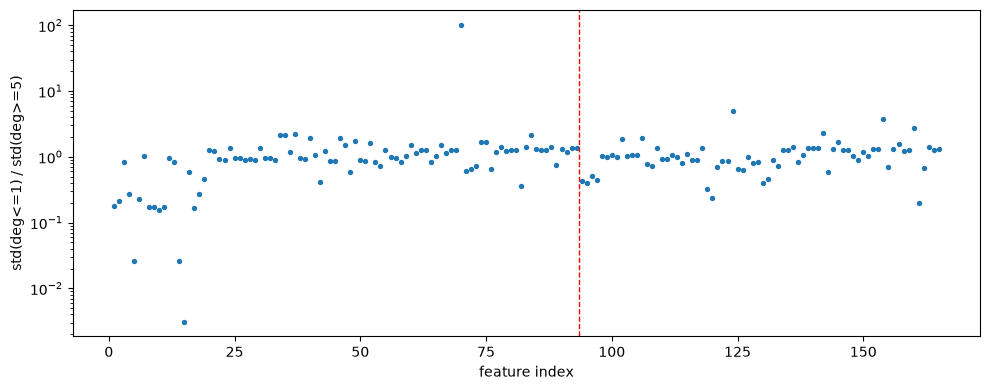

In [ ]:
# Compares each feature's spread for low-degree and high-degree nodes
# The red line separates local features (left) from aggregated
# neighbour features (right)
deg_s = pd.Series(deg, index=node_ids)
row_deg = train_raw[ID].map(deg_s)

lo = train_raw.loc[row_deg <= LOW_DEGREE, FEATURE_COLUMNS].std()
hi = train_raw.loc[row_deg >= HIGH_DEGREE, FEATURE_COLUMNS].std()
ratio_deg = (lo / hi).sort_values()

print(ratio_deg.head(10).to_string())
print(ratio_deg.tail(10).to_string())

_, ax = plt.subplots(figsize=(10, 4))
ax.scatter(np.arange(1, N_FEATURES + 1), ratio_deg.reindex(FEATURE_COLUMNS).values, s=8)
ax.axvline(LOCAL_FEATURE_COUNT + 0.5, color="red", ls="--", lw=1)
ax.set_yscale("log")
ax.set_xlabel("feature index")
ax.set_ylabel(f"std(deg<={LOW_DEGREE}) / std(deg>={HIGH_DEGREE})")
plt.tight_layout()
plt.show()

## 11. Feature Matrices

In [ ]:
# Node-aligned feature matrix for graph models with the
# 165 features plus a last column that flags nodes without features (their values stay 0)
feature_matrix = np.zeros((N, N_FEATURES + 1), dtype=np.float32)
feature_matrix[node_ids.get_indexer(train_raw[ID]), :-1] = train_raw[FEATURE_COLUMNS].to_numpy(np.float32)
feature_matrix[node_ids.get_indexer(test_raw[ID]), :-1] = test_raw[FEATURE_COLUMNS].to_numpy(np.float32)
feature_matrix[:, -1] = (~has_feat_arr).astype(np.float32)

print(f"feature_matrix {feature_matrix.shape}  {feature_matrix.nbytes / 1e6:.0f} MB")

feature_matrix (203769, 166)  135 MB


In [ ]:
# Within-step percentile ranks, computed over observable nodes only
X_rank = np.full((N, N_FEATURES), np.nan, dtype=np.float32)

for s in np.unique(step_all):
    rows = np.flatnonzero((step_all == s) & observable_arr)
    # Skip steps with too few rows for stable ranks.
    if len(rows) < MIN_STEP_ROWS:
        continue
    X_rank[rows] = ((rankdata(feature_matrix[rows, :N_FEATURES], axis=0) - 0.5)
                    / len(rows)).astype(np.float32)

covered = np.isfinite(X_rank[:, 0])
pop = pd.Series(step_all[observable_arr]).value_counts().sort_index()

print(f"feature_rank {X_rank.shape}  {X_rank.nbytes / 1e6:.0f} MB")
print(f"rank coverage {covered.sum():,} / {observable_arr.sum():,} observable nodes")
print(f"train-step population sizes  {pop.loc[:train_hi].min()} - {pop.loc[:train_hi].max()}")
print(f"test-step population sizes   {pop.loc[test_lo:].min()} - {pop.loc[test_lo:].max()}")

feature_rank (203769, 165)  134 MB
rank coverage 46,564 / 46,564 observable nodes
train-step population sizes  206 - 2147
test-step population sizes   471 - 2154


## 12. Modelling frames

In [ ]:
# Split train.csv into labelled and unlabelled rows and record each node's split in
# node_index, which later used to align table rows with graph positions
labelled_mask = train_raw[TARGET].notna()
labelled = train_raw.loc[labelled_mask].reset_index(drop=True)
unlabelled = train_raw.loc[~labelled_mask].reset_index(drop=True).drop(columns=[TARGET])
labelled[TARGET] = labelled[TARGET].astype("Int8")

train_processed = train_raw.copy()
train_processed[TARGET] = train_processed[TARGET].astype("Int8")
train_processed["is_labelled"] = labelled_mask.to_numpy()
test_processed = test_raw.copy()

node_index = pd.DataFrame({
    ID: node_ids.to_numpy(),
    STEP: step_all,
    "component": component_labels.astype(np.int32),
    "has_features": has_feat_arr,
})
node_index["split"] = np.select(
    [
        node_index[ID].isin(set(labelled[ID])),
        node_index[ID].isin(set(unlabelled[ID])),
        node_index[ID].isin(set(test_raw[ID])),
    ],
    ["train_labelled", "train_unlabelled", "test"],
    default="graph_only",
)
node_index["split"] = node_index["split"].astype("category")

# Edge list with integer node positions (src, dst) for graph code
edges_processed = edges_raw.drop_duplicates().reset_index(drop=True)
edges_processed["src"] = node_ids.get_indexer(edges_processed["txId1"])
edges_processed["dst"] = node_ids.get_indexer(edges_processed["txId2"])

for name, frame in [("labelled", labelled), ("unlabelled", unlabelled), ("test", test_processed)]:
    print(f"{name:16} {len(frame):>8,}  steps {frame[STEP].min()}-{frame[STEP].max()}")

print(f"\n{node_index['split'].value_counts().to_string()}")
print(f"\nedges            {len(edges_processed):>8,}  (raw {len(edges_raw):,})")

labelled           31,235  steps 1-35
unlabelled        110,537  steps 1-35
test               15,329  steps 36-49

split
train_unlabelled    110537
graph_only           46668
train_labelled       31235
test                 15329

edges             234,355  (raw 234,355)


## 13. Persist to parquet

In [ ]:
# Save parquet tables, the node-aligned feature and rank
# matrices (.npy) and both adjacency matrices (.npz)
def dump(frame, name):
    out = PROCESSED_DIR / f"{name}.parquet"
    frame.to_parquet(out, engine="pyarrow", compression="zstd", index=False)
    print(f"{name:18} {len(frame):>8,} rows x {frame.shape[1]:>3}  {out.stat().st_size / 1e6:6.1f} MB")

dump(train_processed, "train")
dump(test_processed, "test")
dump(edges_processed, "edges")
dump(node_index, "node_index")
dump(graph_struct, "graph_struct")
dump(sample_submission, "sample_submission")

np.save(PROCESSED_DIR / "feature_matrix.npy", feature_matrix)
np.save(PROCESSED_DIR / "feature_rank.npy", X_rank)
sp.save_npz(PROCESSED_DIR / "adjacency.npz", A)
sp.save_npz(PROCESSED_DIR / "adjacency_und.npz", A_und)

for name, arr in [("feature_matrix", feature_matrix), ("feature_rank", X_rank)]:
    print(f"{name:18} {arr.shape}  "
          f"{(PROCESSED_DIR / (name + '.npy')).stat().st_size / 1e6:.0f} MB")

train               141,772 rows x 169    35.2 MB
test                 15,329 rows x 168     4.7 MB
edges               234,355 rows x   4     3.7 MB
node_index          203,769 rows x   5     0.8 MB
graph_struct        203,769 rows x  14     1.8 MB
sample_submission    15,329 rows x   2     0.0 MB
feature_matrix     (203769, 166)  135 MB
feature_rank       (203769, 165)  134 MB


## 14. Summary

In [ ]:
# Summary of the data: label scarcity, class imbalance,
# no cross-step edges (labels cannot reach test nodes through the graph) and
# low feature coverage in test steps
positive_rate = labelled[TARGET].mean()
cross_step_edges = int((step_all[edges_processed.src.to_numpy()]
                        != step_all[edges_processed.dst.to_numpy()]).sum())

summary = pd.Series({
    "labelled training rows": len(labelled),
    "unlabelled training rows": len(unlabelled),
    "test rows": len(test_processed),
    "features": N_FEATURES,
    "positive rate": round(positive_rate, 4),
    "imbalance ratio": round((1 - positive_rate) / positive_rate, 2),
    "graph nodes": N,
    "graph edges": len(edges_processed),
    "connected components": n_comp,
    "components equal time steps": bool(n_comp == df["step"].nunique()),
    "cross-time-step edges": cross_step_edges,
    "featureless graph nodes": int((~has_feat_arr).sum()),
    "label reachable from test": cross_step_edges > 0,
    "train window coverage": round(tr.coverage.mean(), 3),
    "test window coverage": round(te.coverage.mean(), 3),
    "train window": f"{train_raw[STEP].min()}-{train_hi}",
    "test window": f"{test_lo}-{test_hi}",
    "max forecast horizon": test_hi - train_hi,
})

print(summary.to_string())

labelled training rows          31235
unlabelled training rows       110537
test rows                       15329
features                          165
positive rate                  0.1167
imbalance ratio                  7.57
graph nodes                    203769
graph edges                    234355
connected components               49
components equal time steps      True
cross-time-step edges               0
featureless graph nodes         46668
label reachable from test       False
train window coverage             1.0
test window coverage            0.244
train window                     1-35
test window                     36-49
max forecast horizon               14


# Part 2: Feature Engineering

Builds a time-based validation harness and tests candidate feature blocks (within-step ranks, graph structure, neighbourhood aggregates, deviations, an outlier score, null-importance selection) against the raw features.

A block is adopted only if it beats the raw features on average and on at least 9 of 10 folds; none did. Features the test period has moved beyond are dropped, and the final 162 features are saved with `feature_spec.json` for the prediction part.

## 1. Import Libraries

The imports for this part are in the import cell at the top of the notebook.

## 2. User Configuration

In [ ]:
# simple LightGBM (the selection model) that scores every
# candidate block, so all blocks are compared on equal terms
RANDOM_SEED = 42
N_THREADS = psutil.cpu_count(logical=False) or 8
N_THREADS_XGB = psutil.cpu_count(logical=True) or 16
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

ID, STEP, TARGET = "txId", "time_step", "label"

# competition metric
METRIC = roc_auc_score

# Every evaluation averages two seeds to reduce noise
SEL_SEEDS = (0, 1)

# Selection model: shallow trees (15 leaves), at least 80 rows per leaf and subsampling
# to limit overfitting. n_estimators is only a cap; the tree count actually used is
# SEL_TREES, calibrated in section 8. These parameters become the final model's
# configuration (sel_params)
SEL_PARAMS = dict(n_estimators=2000, learning_rate=0.05, num_leaves=15,
                  min_child_samples=80, colsample_bytree=0.8, subsample=0.9,
                  subsample_freq=1, reg_lambda=0.0, reg_alpha=0.1, max_bin=127,
                  n_jobs=N_THREADS, verbose=-1)

# Early stopping: patience of 200 rounds on the last 4 steps of each training window;
# the chosen count grows by 15% when refitting on the whole window
ES_ROUNDS, ES_INNER, ES_GROW = 200, 4, 1.15

# Fold cut-offs, given as offsets back from the last labelled step (35). Tune folds
# drive decisions and select folds confirm them; the banks share no cut-off
TUNE_OFFSETS = (5, 7, 9, 11, 13, 15, 17, 19, 21, 22)
SELECT_OFFSETS = (6, 10, 14, 18, 20)
FINAL_OFFSETS = (8, 12, 16) # unused

# Percentile of the early-stopping iterations used as the tree count
SEL_TREES_PCTL = 75

# Earlier fold design with a gap before validation, kept only for the comparison in section 9
PLATEAU_OLD = [(10, 26, 30), (10, 31, 35), (15, 26, 30), (15, 31, 35), (20, 26, 30), (20, 31, 35)]

# Settings for the blocks and checks below: number of local features (the first 93),
# null-importance rounds and percentile, Isolation Forest size, rows for the schema
# check, top features aggregated over neighbours, importance trees and drift-check
# sizes
MIN_STEP_ROWS = 30
LOCAL_FEATURE_COUNT = 93
NULL_IMP_ROUNDS, NULL_IMP_PCTL = 30, 75
OUTLIER_TREES, OUTLIER_SAMPLE = 300, 65536
SCHEMA_CHECK_ROWS = 2000
N_TOP_NBR = 24
IMPORTANCE_TREES = 400
ADV_TREES, ADV_ROUNDS, ADV_TRY_TOP, ADV_STOP_AUC = 300, 2, 3, 0.90 # ADV_TRY_TOP & ADV_STOP_AUC unused
MAX_DROPS, PRUNE_TOL = 12, 0.0015 # unused

# Drop a feature when more than 50% of its test values lie outside the training range
OOR_HARD_DROP = 0.50

# Use the GPU for XGBoost when one is available
def detect_device():
    try:
        xgb.XGBClassifier(device="cuda", tree_method="hist", n_estimators=1, verbosity=0).fit(
            np.zeros((8, 2), dtype=np.float32), np.array([0, 1] * 4))
        return "cuda"
    except Exception:
        return "cpu"

DEVICE = detect_device()

# LightGBM 4.7 renamed the early-stopping evaluation arguments; these helpers pass the
# right ones for the installed version
def _lgb_at_least(major, minor):
    try:
        parts = lgb.__version__.split(".")
        return (int(parts[0]), int(parts[1])) >= (major, minor)
    except Exception:
        return False

LGB_EVAL_NEW = _lgb_at_least(4, 7)

def lgb_eval_kwargs(Xv, yv, es):
    cb = [lgb.early_stopping(es, verbose=False)]
    if LGB_EVAL_NEW:
        return dict(eval_X=Xv, eval_y=yv, eval_metric="auc", callbacks=cb)
    return dict(eval_set=[(Xv, yv)], eval_metric="auc", callbacks=cb)

print(f"xgboost {xgb.__version__} | lightgbm {lgb.__version__}")
print(f"device {DEVICE} | lgb threads {N_THREADS} | xgb threads {N_THREADS_XGB}")
print(f"lightgbm eval_X/eval_y api: {LGB_EVAL_NEW}")
print(f"selection model: {SEL_PARAMS['num_leaves']} leaves, "
      f"min_child {SEL_PARAMS['min_child_samples']}, lr {SEL_PARAMS['learning_rate']}")

xgboost 3.4.1 | lightgbm 4.7.0
device cuda | lgb threads 8 | xgb threads 16
lightgbm eval_X/eval_y api: True
selection model: 15 leaves, min_child 80, lr 0.05


## 3. Loading Data

In [ ]:
# Load the preprocessing outputs. feature_matrix and feature_rank are node-aligned and memory-mapped to save RAM
train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
test = pd.read_parquet(PROCESSED_DIR / "test.parquet")
edges = pd.read_parquet(PROCESSED_DIR / "edges.parquet")
node_index = pd.read_parquet(PROCESSED_DIR / "node_index.parquet")
graph_struct = pd.read_parquet(PROCESSED_DIR / "graph_struct.parquet")

A_und = sp.load_npz(PROCESSED_DIR / "adjacency_und.npz")
X = np.load(PROCESSED_DIR / "feature_matrix.npy", mmap_mode="r")
X_rank = np.load(PROCESSED_DIR / "feature_rank.npy", mmap_mode="r")

assert X.shape[0] == len(node_index) == X_rank.shape[0], "matrices and node_index are out of sync"

print(f"train {train.shape} | test {test.shape} | edges {edges.shape}")
print(f"feature_matrix {X.shape} | feature_rank {X_rank.shape}")

train (141772, 169) | test (15329, 168) | edges (234355, 4)
feature_matrix (203769, 166) | feature_rank (203769, 165)


## 4. Checking if edges cross time steps

In [ ]:
# Confirm that no edge crosses time steps
SRC, DST = edges.columns[:2]
step = node_index.set_index(ID)[STEP]

e = edges.assign(src_step=edges[SRC].map(step), dst_step=edges[DST].map(step))
cross = e["src_step"] != e["dst_step"]

lab_steps = set(train.loc[train["is_labelled"], STEP].unique())
test_steps = set(test[STEP].unique())

print(f"edges            : {len(e):,}")
print(f"cross-step edges : {cross.sum():,} ({cross.mean() * 100:.2f}%)")
print(f"labelled steps   : {min(lab_steps)}-{max(lab_steps)}")
print(f"test steps       : {min(test_steps)}-{max(test_steps)}")
print(f"labelled neighbours reachable from any test node: {len(lab_steps & test_steps) > 0}")

edges            : 234,355
cross-step edges : 0 (0.00%)
labelled steps   : 1-35
test steps       : 36-49
labelled neighbours reachable from any test node: False


## 5. Feature Alignment

In [ ]:
# Check that the node-aligned feature matrix matches train.csv row for row and that its
# flag column marks exactly the featureless nodes, before graph features are built from it
NON_FEAT = {ID, STEP, TARGET, "is_labelled", "index"}
FEATS = [c for c in train.columns if c not in NON_FEAT]
R_FEATS = [f"r_{c}" for c in FEATS]
N_FEATURES = len(FEATS)
FLAG_COL = N_FEATURES

pos = pd.Series(np.arange(len(node_index)), index=node_index[ID])
has_feat = node_index["has_features"].to_numpy().astype(bool)

flag_ok = np.array_equal(np.asarray(X[:, FLAG_COL]), (~has_feat).astype(np.float32))
probe = pos.loc[train[ID].iloc[:SCHEMA_CHECK_ROWS]].to_numpy()
delta = np.abs(np.asarray(X[probe, :N_FEATURES])
               - train[FEATS].iloc[:SCHEMA_CHECK_ROWS].to_numpy(np.float32)).max()

assert flag_ok and delta == 0, "feature_matrix does not match the train schema"

print(f"features {N_FEATURES} | missing-feature flag at column {FLAG_COL}")
print(f"featured nodes {has_feat.sum():,} / {len(has_feat):,}")

features 165 | missing-feature flag at column 165
featured nodes 157,101 / 203,769


## 6. Neighbourhood Coverage

In [ ]:
# Observable-neighbour coverage (labelled training rows plus test rows)
observable = node_index["split"].isin(["train_labelled", "test"]).to_numpy()
m = observable.astype(np.float32)
deg = graph_struct["g_deg"].to_numpy()
cnt = np.asarray(A_und @ m).ravel()

step_arr = node_index[STEP].to_numpy()
te_lo = int(test[STEP].min())

for name, sel in [("train steps", observable & (step_arr < te_lo)),
                  ("test steps", observable & (step_arr >= te_lo))]:
    d, c = deg[sel], cnt[sel]
    print(f"{name:12} n={sel.sum():>7,}  isolated: {(d == 0).mean() * 100:5.1f}%  "
          f"zero observable nbrs: {(c == 0).mean() * 100:5.1f}%  "
          f"median observable nbrs: {np.median(c):.0f}  "
          f"mean usable frac: {np.divide(c, np.maximum(d, 1)).mean():.2f}")

train steps  n= 31,235  isolated:   0.0%  zero observable nbrs:  21.8%  median observable nbrs: 1  mean usable frac: 0.63
test steps   n= 15,329  isolated:   0.0%  zero observable nbrs:  25.4%  median observable nbrs: 1  mean usable frac: 0.61


## 7. Modelling Frames

In [ ]:
# Modelling frames: labelled rows (lab), test rows and unlabelled rows, each with the
# within-step rank features (prefix r_) attached for the rank test in section 10
def with_rank(frame):
    frame = frame.drop(columns=[c for c in R_FEATS if c in frame.columns]).reset_index(drop=True)
    ranks = np.asarray(X_rank[pos.loc[frame[ID]].to_numpy()])
    return pd.concat([frame, pd.DataFrame(ranks, columns=R_FEATS)], axis=1)

lab = train[train["is_labelled"]].copy()
lab[TARGET] = lab[TARGET].astype(np.int8)
unl = train[~train["is_labelled"]].drop(columns=[TARGET])
lab, test, unl = with_rank(lab), with_rank(test), with_rank(unl)

assert lab[R_FEATS].notna().all().all() and test[R_FEATS].notna().all().all(), \
    "rank features contain gaps"

# The illicit rate per step ranges from under 1% to about 36%, an early sign of drift over time
per_step = (lab.groupby(STEP)[TARGET].agg(n="size", pos="sum")
               .assign(rate=lambda d: d.pos / d.n))
print(per_step.round(4).to_string())
print(f"\nlab {lab.shape}   test {test.shape}   unlabelled {unl.shape}")

              n  pos    rate
time_step                   
1          2147   17  0.0079
2          1117   18  0.0161
3          1279   11  0.0086
4          1440   30  0.0208
5          1882    8  0.0043
6           485    5  0.0103
7          1203  102  0.0848
8          1165   67  0.0575
9           778  248  0.3188
10          972   18  0.0185
11          696  131  0.1882
12          506   16  0.0316
13          809  291  0.3597
14          417   43  0.1031
15          618  147  0.2379
16          530  128  0.2415
17          811   99  0.1221
18          389   52  0.1337
19          745   80  0.1074
20          900  260  0.2889
21          641  100  0.1560
22         1763  158  0.0896
23         1187   53  0.0447
24         1126  137  0.1217
25          594  118  0.1987
26          517   96  0.1857
27          206   24  0.1165
28          284   85  0.2993
29         1174  329  0.2802
30          524   83  0.1584
31          710  106  0.1493
32         1323  342  0.2585
33          44

## 8. Validation Harness

In [ ]:
# Time-based folds that mimic the test set: train on steps up to a cut-off, validate on
# the following steps up to the 14-step horizon (capped at step 35). A random K-fold
# split would mix future rows into training
STEP_MAX = int(lab[STEP].max())
HORIZON = int(test[STEP].max()) - STEP_MAX

def make_folds(offsets):
    return [(STEP_MAX - o, STEP_MAX - o + 1, min(STEP_MAX - o + HORIZON, STEP_MAX))
            for o in offsets]

# Tune folds (10 cut-offs) drive decisions; select folds (5 other cut-offs) confirm them
FOLDS = make_folds(TUNE_OFFSETS)
FOLDS_SELECT = make_folds(SELECT_OFFSETS)

all_offsets = TUNE_OFFSETS + SELECT_OFFSETS
assert len(set(all_offsets)) == len(all_offsets), "fold banks share a training cut"

print(f"labelled window 1-{STEP_MAX}, forecast horizon {HORIZON} steps")
for nm, fb in [("FOLDS (tune)", FOLDS), ("FOLDS_SELECT", FOLDS_SELECT)]:
    print(f"{nm:<14} {len(fb):>2} folds  cuts {sorted(a for a, _, _ in fb)}")
print("both banks validate on overlapping rows, so neither is out-of-sample")

labelled window 1-35, forecast horizon 14 steps
FOLDS (tune)   10 folds  cuts [13, 14, 16, 18, 20, 22, 24, 26, 28, 30]
FOLDS_SELECT    5 folds  cuts [15, 17, 21, 25, 29]
both banks validate on overlapping rows, so neither is out-of-sample


In [ ]:
# Tree-count calibration and the evaluation helpers behind every feature decision.
# Inner early-stopping split that keeps time order: the last ES_INNER steps of a
# training window act as validation
def inner_split(tr, inner=ES_INNER):
    steps = tr[STEP].to_numpy()
    y = tr[TARGET].to_numpy()
    tr_m = steps <= steps.max() - inner
    va_m = ~tr_m
    if tr_m.sum() < 500 or va_m.sum() < 200 or len(np.unique(y[va_m])) < 2:
        return None
    return tr_m

# early-stop on each tune fold, then take the 75th
# percentile of the best iterations, grown by 15% (SEL_TREES)
cal = []
for tr_hi, _, _ in FOLDS:
    tr_ = lab[lab[STEP] <= tr_hi]
    Xc = tr_[FEATS].to_numpy(np.float32)
    yc = tr_[TARGET].to_numpy(np.int8)
    mask = inner_split(tr_)
    if mask is None:
        continue
    m0 = lgb.LGBMClassifier(**dict(SEL_PARAMS, n_estimators=4000, random_state=0)).fit(
        Xc[mask], yc[mask], **lgb_eval_kwargs(Xc[~mask], yc[~mask], ES_ROUNDS))
    cal.append(int(m0.best_iteration_))

SEL_TREES = int(np.percentile(cal, SEL_TREES_PCTL) * ES_GROW)
print(f"best_iteration across tuning folds: {sorted(cal)}")
print(f"SEL_TREES = p{SEL_TREES_PCTL} x {ES_GROW} = {SEL_TREES} at lr {SEL_PARAMS['learning_rate']}")

# The selection model as a fit-and-predict function (no recency weighting here)
def sel_fit(params=None, seed=0):
    def _f(tr, va, f):
        p = dict(SEL_PARAMS, n_estimators=SEL_TREES, random_state=seed)
        p.update(params or {})
        mdl = lgb.LGBMClassifier(**p).fit(tr[f].to_numpy(np.float32),
                                          tr[TARGET].to_numpy(np.int8))
        return mdl.predict_proba(va[f].to_numpy(np.float32))[:, 1]
    return _f

# XGBoost counterpart, used only to cross-check the final feature set
def xgb_sel_fit(params=None, seed=0):
    def _f(tr, va, f):
        p = dict(n_estimators=700, max_depth=6, learning_rate=0.03, subsample=0.8,
                 colsample_bytree=0.8, tree_method="hist", device=DEVICE,
                 n_jobs=N_THREADS_XGB, random_state=seed)
        p.update(params or {})
        clf = xgb.XGBClassifier(**p)
        clf.fit(tr[f].to_numpy(np.float32), tr[TARGET].to_numpy(np.int8))
        clf.set_params(device="cpu")
        return clf.predict_proba(va[f].to_numpy(np.float32))[:, 1]
    return _f

# Mean ROC AUC over folds; predictions from several seeds are averaged as ranks
def eval_folds(builder, features, folds, frame=None, seeds=SEL_SEEDS, wrap=None):
    frame = lab if frame is None else frame
    out = []
    for tr_hi, v_lo, v_hi in folds:
        tr_ = frame[frame[STEP] <= tr_hi]
        va_ = frame[frame[STEP].between(v_lo, v_hi)]
        if len(tr_) == 0 or va_[TARGET].nunique() < 2:
            continue
        preds = []
        for sd in seeds:
            fn = builder(seed=sd)
            fn = wrap(fn) if wrap is not None else fn
            preds.append(rankdata(fn(tr_, va_, features)) / len(va_))
        out.append(METRIC(va_[TARGET], np.mean(preds, axis=0)))
    return float(np.mean(out)), out

# Tune and select AUC, worst fold and spread for one feature set
def report_block(name, builder, features, frame=None, seeds=SEL_SEEDS, wrap=None, select=True):
    s, sf = eval_folds(builder, features, FOLDS, frame, seeds, wrap)
    h = np.nan
    if select:
        h, _ = eval_folds(builder, features, FOLDS_SELECT, frame, seeds, wrap)
    print(f"{name:<30} n={len(features):>3}  tune {s:.4f}  select {h:.4f}  "
          f"worst {min(sf):.4f}  std {np.std(sf):.4f}")
    return s, h, sf

# Candidate against baseline on the same folds. A block is adopted only with a positive
# mean gain and a significant sign test
def paired_compare(name, cand_feats, base_feats, builder=sel_fit, folds=None,
                   seeds=SEL_SEEDS, cand_wrap=None, base_wrap=None):
    folds = FOLDS if folds is None else folds
    _, c = eval_folds(builder, cand_feats, folds, None, seeds, cand_wrap)
    _, b = eval_folds(builder, base_feats, folds, None, seeds, base_wrap)
    d = np.array(c) - np.array(b)
    wins = int((d > 0).sum())
    p_sign = binomtest(wins, len(d), 0.5, alternative="greater").pvalue
    p_t = float(ttest_rel(c, b).pvalue) if len(d) > 1 else np.nan
    print(f"{name:<30} delta {d.mean():+.4f}  sd {d.std(ddof=1):.4f}  "
          f"won {wins}/{len(d)}  sign p {p_sign:.3f}  paired-t p {p_t:.3f}")
    return {"name": name, "delta": float(d.mean()), "sd": float(d.std(ddof=1)),
            "wins": wins, "n": len(d), "p_sign": float(p_sign), "p_t": p_t,
            "per_fold": d.round(4).tolist()}

best_iteration across tuning folds: [80, 106, 126, 130, 140, 160, 171, 197, 381, 457]
SEL_TREES = p75 x 1.15 = 219 at lr 0.05


## 9. Harness Comparison

In [ ]:
# Compare the old gapped folds with the new horizon-matched folds, then measure the
# noise floor: same model with different seeds
old_s, old_f = eval_folds(sel_fit, FEATS, PLATEAU_OLD)
new_s, new_f = eval_folds(sel_fit, FEATS, FOLDS)

print(f"old PLATEAU (gapped, small train) {old_s:.4f}  spread {np.ptp(old_f):.4f}")
print(f"new FOLDS (horizon 1-{HORIZON})            {new_s:.4f}  spread {np.ptp(new_f):.4f}")
print(pd.DataFrame({"fold": [f"{a} to {b}-{c}" for a, b, c in FOLDS],
                    "auc": new_f}).round(4).to_string(index=False))

null_a = eval_folds(sel_fit, FEATS, FOLDS, seeds=(0, 1))[1]
null_b = eval_folds(sel_fit, FEATS, FOLDS, seeds=(2, 3))[1]
null_d = np.array(null_a) - np.array(null_b)
print(f"\nnoise floor (same model, different seeds): mean {null_d.mean():+.4f}  "
      f"sd {null_d.std(ddof=1):.4f}  se {null_d.std(ddof=1) / np.sqrt(len(null_d)):.4f}")
print(f"a real gain must clear roughly {2 * null_d.std(ddof=1) / np.sqrt(len(null_d)):.4f} "
      f"on {len(FOLDS)} folds")

old PLATEAU (gapped, small train) 0.8495  spread 0.0966
new FOLDS (horizon 1-14)            0.9581  spread 0.1012
       fold    auc
30 to 31-35 0.9983
28 to 29-35 0.9965
26 to 27-35 0.9970
24 to 25-35 0.9966
22 to 23-35 0.8971
20 to 21-34 0.9059
18 to 19-32 0.8996
16 to 17-30 0.9405
14 to 15-28 0.9742
13 to 14-27 0.9756

noise floor (same model, different seeds): mean +0.0002  sd 0.0037  se 0.0012
a real gain must clear roughly 0.0023 on 10 folds


## 10. Within-step Rank Features

In [ ]:
# Within-step rank block: ranks alone, and raw features plus ranks, against the raw features
CANDIDATES = {"raw": FEATS, "rank": R_FEATS, "raw + rank": FEATS + R_FEATS}
for name, fs in CANDIDATES.items():
    report_block(name, sel_fit, fs)

block_tests = [paired_compare(f"{name} vs raw", fs, FEATS)
               for name, fs in CANDIDATES.items() if name != "raw"]
print(f"\n{pd.DataFrame(block_tests)[['name', 'delta', 'wins', 'n', 'p_sign', 'p_t']].round(4).to_string(index=False)}")

raw                            n=165  tune 0.9581  select 0.9489  worst 0.8971  std 0.0410
rank                           n=165  tune 0.8796  select 0.8690  worst 0.8313  std 0.0398
raw + rank                     n=330  tune 0.9580  select 0.9547  worst 0.8945  std 0.0402
rank vs raw                    delta -0.0785  sd 0.0490  won 0/10  sign p 1.000  paired-t p 0.001
raw + rank vs raw              delta -0.0001  sd 0.0069  won 4/10  sign p 0.828  paired-t p 0.950

             name   delta  wins  n  p_sign    p_t
      rank vs raw -0.0785     0 10  1.0000 0.0007
raw + rank vs raw -0.0001     4 10  0.8281 0.9500


In [ ]:
# Adopt the rank block only if it passes the sign test; otherwise the base set stays the raw features
rank_test = next(t for t in block_tests if t["name"].startswith("raw + rank"))
RANK_OK = rank_test["delta"] > 0 and rank_test["p_sign"] < 0.05
BASE_SET = (FEATS + R_FEATS) if RANK_OK else FEATS
print(f"BASE_SET: {len(BASE_SET)} features   rank block adopted: {RANK_OK}")

BASE_SET: 165 features   rank block adopted: False


## 11. Graph Structural and Neighbourhood Features

In [ ]:
# Graph blocks. Structural features come from preprocessing. Neighbourhood features are
# the mean and spread, over observable neighbours only, of the within-step ranks of the
# 24 most important features
G_FEATS = [c for c in graph_struct.columns if c != ID]

# Feature importance is fitted on steps up to 13 only, before every validation window,
# so choosing the top features cannot leak validation labels
IMP_CUT = STEP_MAX - max(all_offsets)
imp_rows = lab[lab[STEP] <= IMP_CUT]

imp = pd.Series(
    lgb.LGBMClassifier(**dict(SEL_PARAMS, n_estimators=IMPORTANCE_TREES, random_state=0)).fit(
        imp_rows[FEATS].to_numpy(np.float32), imp_rows[TARGET].to_numpy(np.int8)).feature_importances_,
    index=FEATS).sort_values(ascending=False)
TOP = [FEATS.index(c) for c in imp.head(N_TOP_NBR).index]

# Zero out non-observable nodes so they do not enter neighbour statistics
Rz = np.nan_to_num(np.asarray(X_rank), nan=0.0) * m[:, None]
safe = np.maximum(cnt, 1)[:, None]

# Neighbour mean and standard deviation over observable neighbours; NaN when a node has none
nm = (A_und @ Rz[:, TOP]) / safe
ns = np.sqrt(np.maximum((A_und @ (Rz[:, TOP] ** 2)) / safe - nm ** 2, 0))
nm[cnt == 0] = np.nan
ns[cnt == 0] = np.nan

NM = [f"nm_{FEATS[i]}" for i in TOP]
NS = [f"ns_{FEATS[i]}" for i in TOP]
nbr = pd.DataFrame(np.hstack([nm, ns]).astype(np.float32), columns=NM + NS)

# Coverage features: share and count of observable neighbours
nbr["nbr_cov"] = np.divide(cnt, np.maximum(deg, 1)).astype(np.float32)
nbr["nbr_n"] = cnt.astype(np.float32)
nbr[ID] = node_index[ID].to_numpy()
N_FEATS = NM + NS + ["nbr_cov", "nbr_n"]

del Rz, nm, ns
print(f"importance fit on steps 1-{IMP_CUT} ({len(imp_rows):,} rows)")
print(f"graph structural {len(G_FEATS)}   neighbourhood {len(N_FEATS)}")

importance fit on steps 1-13 (14,479 rows)
graph structural 13   neighbourhood 50


In [ ]:
# Labelled-subgraph block: counts of observable in- and out-neighbours and the size of
# the node's component within the observable subgraph
A_dir = sp.load_npz(PROCESSED_DIR / "adjacency.npz").tocsr()
obs_idx = np.flatnonzero(observable)
_, comp = sp.csgraph.connected_components(A_und[obs_idx][:, obs_idx], directed=False)
obs_comp = np.zeros(len(node_index), dtype=np.float32)
obs_comp[obs_idx] = np.bincount(comp)[comp]

lab_sub = pd.DataFrame({ID: node_index[ID].to_numpy(),
                        "obs_in": np.asarray(A_dir.T @ m).ravel().astype(np.float32),
                        "obs_out": np.asarray(A_dir @ m).ravel().astype(np.float32),
                        "obs_comp": obs_comp})
S_FEATS = [c for c in lab_sub.columns if c != ID]
L_FEATS = S_FEATS + ["nbr_cov"]

chk = lab_sub.assign(nbr_cov=nbr["nbr_cov"].to_numpy()).set_index(ID)
print(pd.DataFrame({"licit": chk.loc[lab.loc[lab[TARGET] == 0, ID]].mean(),
                    "illicit": chk.loc[lab.loc[lab[TARGET] == 1, ID]].mean(),
                    "test": chk.loc[test[ID]].mean()}).round(3).to_string())

               licit     illicit        test
obs_in      0.814000    0.399000    0.830000
obs_out     0.811000    0.420000    0.830000
obs_comp  315.001007  167.578003  432.458008
nbr_cov     0.653000    0.463000    0.609000


In [ ]:
# Join every graph block onto the frames, then score each block against the base set
# with the paired test
def with_graph(frame):
    frame = frame.drop(columns=[c for c in G_FEATS + N_FEATS + S_FEATS if c in frame.columns])
    return (frame.merge(graph_struct, on=ID, how="left").merge(nbr, on=ID, how="left")
                 .merge(lab_sub, on=ID, how="left"))

lab, test, unl = with_graph(lab), with_graph(test), with_graph(unl)

assert lab[G_FEATS].notna().all().all() and test[G_FEATS].notna().all().all(), \
    "structural features contain gaps after merge"

BLOCKS = {"base": BASE_SET, "structural": BASE_SET + G_FEATS,
          "neighbourhood": BASE_SET + N_FEATS, "both": BASE_SET + G_FEATS + N_FEATS,
          "labelled subgraph": BASE_SET + L_FEATS}
BLOCK_CV = {name: report_block(name, sel_fit, fs)[0] for name, fs in BLOCKS.items()}

graph_tests = [paired_compare(f"{name} vs base", fs, BASE_SET)
               for name, fs in BLOCKS.items() if name != "base"]
print(f"\n{pd.DataFrame(graph_tests)[['name', 'delta', 'wins', 'n', 'p_sign', 'p_t']].round(4).to_string(index=False)}")

base                           n=165  tune 0.9581  select 0.9489  worst 0.8971  std 0.0410
structural                     n=178  tune 0.9567  select 0.9494  worst 0.8915  std 0.0424
neighbourhood                  n=215  tune 0.9537  select 0.9469  worst 0.8744  std 0.0455
both                           n=228  tune 0.9550  select 0.9464  worst 0.8890  std 0.0438
labelled subgraph              n=169  tune 0.9538  select 0.9478  worst 0.8715  std 0.0465
structural vs base             delta -0.0015  sd 0.0053  won 4/10  sign p 0.828  paired-t p 0.403
neighbourhood vs base          delta -0.0045  sd 0.0072  won 3/10  sign p 0.945  paired-t p 0.080
both vs base                   delta -0.0031  sd 0.0058  won 4/10  sign p 0.828  paired-t p 0.122
labelled subgraph vs base      delta -0.0044  sd 0.0078  won 4/10  sign p 0.828  paired-t p 0.110

                     name   delta  wins  n  p_sign    p_t
       structural vs base -0.0015     4 10  0.8281 0.4035
    neighbourhood vs base -0.0045   

In [ ]:
# Keep the best block that passes the sign test; if none passes, the base (raw) features remain
passing = [t for t in graph_tests if t["delta"] > 0 and t["p_sign"] < 0.05]
win = max(passing, key=lambda t: t["delta"])["name"].split(" vs ")[0] if passing else "base"
CAND_SET = BLOCKS[win]
print(f"selected block: {win}   n={len(CAND_SET)}   tune {BLOCK_CV[win]:.4f}   "
      f"candidates clearing the sign test: {[t['name'] for t in passing] or 'none'}")

selected block: base   n=165   tune 0.9581   candidates clearing the sign test: none


## 12. Deviation, Outlier and Null-importance Blocks

In [ ]:
# Deviation block: each aggregated feature minus its most correlated local feature, i.e.
# how far a transaction stands out from its neighbourhood
LOCAL = FEATS[:LOCAL_FEATURE_COUNT]
AGG = FEATS[LOCAL_FEATURE_COUNT:]

Z = lab[FEATS].to_numpy(np.float32)
Zc = (Z - Z.mean(0)) / (Z.std(0) + 1e-9)
C = np.abs(Zc[:, len(LOCAL):].T @ Zc[:, :len(LOCAL)]) / len(Z)
partner = {AGG[i]: LOCAL[int(np.argmax(C[i]))] for i in range(len(AGG))}

D_FEATS = [f"d_{a}" for a in AGG]
for frame in (lab, test, unl):
    dev = {f"d_{a}": frame[a].to_numpy(np.float32) - frame[partner[a]].to_numpy(np.float32)
           for a in AGG}
    for k, v in dev.items():
        frame[k] = v

print(f"local {len(LOCAL)}  aggregated {len(AGG)}  deviation features {len(D_FEATS)}")
print(f"mean |corr| of matched pairs {np.mean([C[i].max() for i in range(len(AGG))]):.3f}")

local 93  aggregated 72  deviation features 72
mean |corr| of matched pairs 0.245


In [ ]:
# Outlier block: an Isolation Forest fitted on labelled and test rows without labels;
# its anomaly score is a single candidate feature
iso = IsolationForest(n_estimators=OUTLIER_TREES, max_samples=min(OUTLIER_SAMPLE, len(lab)),
                      random_state=RANDOM_SEED, n_jobs=N_THREADS)
iso.fit(np.vstack([lab[FEATS].to_numpy(np.float32), test[FEATS].to_numpy(np.float32)]))

O_FEATS = ["o_score"]
lab["o_score"] = iso.score_samples(lab[FEATS].to_numpy(np.float32)).astype(np.float32)
test["o_score"] = iso.score_samples(test[FEATS].to_numpy(np.float32)).astype(np.float32)
unl["o_score"] = iso.score_samples(unl[FEATS].to_numpy(np.float32)).astype(np.float32)

print(f"outlier score  lab mean {lab['o_score'].mean():.4f}  test mean {test['o_score'].mean():.4f}")
print(f"               illicit {lab.loc[lab[TARGET] == 1, 'o_score'].mean():.4f}  "
      f"licit {lab.loc[lab[TARGET] == 0, 'o_score'].mean():.4f}")

outlier score  lab mean -0.3766  test mean -0.3740
               illicit -0.3428  licit -0.3811


In [ ]:
# Null-importance selection: compare each feature's importance with its importance when
# the labels are shuffled, and keep features above the 75th percentile of the shuffled runs
Xn = lab[CAND_SET].to_numpy(np.float32)
yn = lab[TARGET].to_numpy(np.int8)
real_imp = lgb.LGBMClassifier(**dict(SEL_PARAMS, n_estimators=SEL_TREES,
                                     random_state=0)).fit(Xn, yn).feature_importances_

null_imp = np.zeros((NULL_IMP_ROUNDS, len(CAND_SET)))
rs = np.random.default_rng(RANDOM_SEED)
for r in range(NULL_IMP_ROUNDS):
    null_imp[r] = lgb.LGBMClassifier(**dict(SEL_PARAMS, n_estimators=SEL_TREES,
                                            random_state=r)).fit(
        Xn, rs.permutation(yn)).feature_importances_

thresh = np.percentile(null_imp, NULL_IMP_PCTL, axis=0)
NULL_KEEP = [c for c, r, t in zip(CAND_SET, real_imp, thresh) if r > t]
print(f"null-importance keeps {len(NULL_KEEP)} of {len(CAND_SET)} features")
print(f"dropped: {[c for c in CAND_SET if c not in NULL_KEEP][:20]}")

null-importance keeps 44 of 165 features
dropped: ['feat_4', 'feat_6', 'feat_7', 'feat_9', 'feat_10', 'feat_11', 'feat_12', 'feat_13', 'feat_15', 'feat_16', 'feat_17', 'feat_18', 'feat_19', 'feat_20', 'feat_21', 'feat_22', 'feat_24', 'feat_25', 'feat_26', 'feat_27']


In [ ]:
# Paired tests for the deviation, outlier and null-importance candidates; the best one
# that passes the sign test would replace the candidate set
STAGE2 = {"deviation": CAND_SET + D_FEATS,
          "outlier": CAND_SET + O_FEATS,
          "deviation + outlier": CAND_SET + D_FEATS + O_FEATS,
          "null-importance subset": NULL_KEEP}

s2_tests = [paired_compare(name, fs, CAND_SET) for name, fs in STAGE2.items()]
print(f"\n{pd.DataFrame(s2_tests)[['name', 'delta', 'sd', 'wins', 'n', 'p_sign', 'p_t']].round(4).to_string(index=False)}")

s2_pass = [t for t in s2_tests if t["delta"] > 0 and t["p_sign"] < 0.05]
if s2_pass:
    CAND_SET = STAGE2[max(s2_pass, key=lambda t: t["delta"])["name"]]
print(f"\nadopted: {[t['name'] for t in s2_pass] or 'none'}   CAND_SET now {len(CAND_SET)}")

deviation                      delta -0.0067  sd 0.0112  won 2/10  sign p 0.989  paired-t p 0.089
outlier                        delta -0.0054  sd 0.0077  won 4/10  sign p 0.828  paired-t p 0.053
deviation + outlier            delta -0.0158  sd 0.0244  won 0/10  sign p 1.000  paired-t p 0.070
null-importance subset         delta -0.0030  sd 0.0085  won 5/10  sign p 0.623  paired-t p 0.289

                  name   delta     sd  wins  n  p_sign    p_t
             deviation -0.0067 0.0112     2 10  0.9893 0.0891
               outlier -0.0054 0.0077     4 10  0.8281 0.0530
   deviation + outlier -0.0158 0.0244     0 10  1.0000 0.0702
null-importance subset -0.0030 0.0085     5 10  0.6230 0.2890

adopted: none   CAND_SET now 165


## 13. Drift Diagnostics

In [ ]:
# Drift check by adversarial validation: a classifier tries to tell training rows from
# test rows. An AUC near 0.5 means similar distributions; an AUC of 1.0 means the test
# period differs strongly from training
def adversarial(features, n_rounds=ADV_ROUNDS):
    aucs, imps = [], []
    for sd in range(n_rounds):
        adv = pd.concat([lab[features].assign(_t=0), test[features].assign(_t=1)],
                        ignore_index=True)
        Xa = adv[features].to_numpy(np.float32)
        ya = adv["_t"].to_numpy()
        Xtr, Xva, ytr, yva = train_test_split(Xa, ya, test_size=0.3, stratify=ya, random_state=sd)
        c = xgb.XGBClassifier(n_estimators=ADV_TREES, max_depth=5, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                              device=DEVICE, n_jobs=N_THREADS_XGB, random_state=sd)
        c.fit(Xtr, ytr)
        c.set_params(device="cpu")
        aucs.append(roc_auc_score(yva, c.predict_proba(Xva)[:, 1]))
        imps.append(pd.Series(c.feature_importances_, index=features))
    return float(np.mean(aucs)), pd.concat(imps, axis=1).mean(1).sort_values(ascending=False)


raw_adv, raw_imp = adversarial(FEATS)
cand_adv, _ = adversarial(CAND_SET)
print(f"adversarial AUC raw {N_FEATURES}      {raw_adv:.4f}")
print(f"adversarial AUC candidate    {cand_adv:.4f}   n={len(CAND_SET)}")
print(raw_imp.head(10).round(4).to_string())

C:\Users\iiank-laptop\AppData\Local\Temp\ipykernel_19708\2388644360.py:19: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return float(np.mean(aucs)), pd.concat(imps, axis=1).mean(1).sort_values(ascending=False)


adversarial AUC raw 165      1.0000
adversarial AUC candidate    1.0000   n=165
feat_101    0.5323
feat_103    0.2598
feat_136    0.1406
feat_61     0.0047
feat_90     0.0044
feat_138    0.0032
feat_18     0.0029
feat_89     0.0029
feat_137    0.0029
feat_23     0.0029


C:\Users\iiank-laptop\AppData\Local\Temp\ipykernel_19708\2388644360.py:19: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return float(np.mean(aucs)), pd.concat(imps, axis=1).mean(1).sort_values(ascending=False)


In [ ]:
# Per-feature drift: share of test values outside the training range (out_of_range),
# variation between steps relative to variation within steps (time_ratio), and
# adversarial importance
lo_tr, hi_tr = lab[FEATS].min(), lab[FEATS].max()
oor = ((test[FEATS] < lo_tr) | (test[FEATS] > hi_tr)).mean().sort_values(ascending=False)

grp = lab.groupby(STEP)[FEATS]
time_ratio = (grp.mean().std() / (grp.std().mean() + 1e-9)).sort_values(ascending=False)

drift = pd.DataFrame({"out_of_range": oor, "time_ratio": time_ratio[oor.index],
                      "adv_imp": raw_imp[oor.index]})
print(drift.head(15).round(4).to_string())
print(f"\n>50% out of range: {(oor > 0.50).sum()}   >10%: {(oor > 0.10).sum()}   "
      f">1%: {(oor > 0.01).sum()}")

          out_of_range  time_ratio  adv_imp
feat_101        0.9954     21.0529   0.5323
feat_103        0.9943     12.5795   0.2598
feat_100        0.9921      6.3848   0.0024
feat_106        0.0620      1.3864   0.0002
feat_109        0.0542      1.1352   0.0001
feat_107        0.0199      0.7526   0.0004
feat_144        0.0068      0.3036   0.0010
feat_108        0.0042      0.2734   0.0000
feat_113        0.0034      0.5128   0.0000
feat_145        0.0028      0.3736   0.0004
feat_143        0.0027      0.3411   0.0003
feat_115        0.0011      0.6369   0.0001
feat_112        0.0010      0.5993   0.0001
feat_2          0.0010      0.2692   0.0022
feat_1          0.0010      0.2145   0.0018

>50% out of range: 3   >10%: 3   >1%: 6


## 14. Out-of-range Feature Drop

In [ ]:
# Drop features whose test values mostly lie outside the training range
HARD_DROP = sorted([c for c in CAND_SET if c in oor.index and oor[c] > OOR_HARD_DROP],
                   key=lambda c: -oor[c])
MODEL_FEATS = [c for c in CAND_SET if c not in HARD_DROP]

print(f"hard-dropped {len(HARD_DROP)} features with over {OOR_HARD_DROP:.0%} of test values "
      f"outside the training range:")
for c in HARD_DROP:
    print(f"   {c:<12} out of range {oor[c]:.4f}")
print("a tree cannot split beyond its training range, so no fold can measure this cost")
print(f"kept {len(MODEL_FEATS)}   max out-of-range still in the model: "
      f"{max(oor[c] for c in MODEL_FEATS if c in oor.index):.4f}")

hard-dropped 3 features with over 50% of test values outside the training range:
   feat_101     out of range 0.9954
   feat_103     out of range 0.9943
   feat_100     out of range 0.9921
a tree cannot split beyond its training range, so no fold can measure this cost
kept 162   max out-of-range still in the model: 0.0620


In [ ]:
# Final check: adversarial AUC after the drop, and fold AUC of the final set against all
# raw features (LightGBM, with XGBoost as a cross-check)
final_adv, _ = adversarial(MODEL_FEATS)
f_s, f_h, _ = report_block("final", sel_fit, MODEL_FEATS, seeds=(0, 1, 2))
r_s, _, _ = report_block("raw only", sel_fit, FEATS, seeds=(0, 1, 2))

x_f, _, _ = report_block("final / xgboost check", xgb_sel_fit, MODEL_FEATS, seeds=(0, 1))
x_r, _, _ = report_block("raw only / xgboost check", xgb_sel_fit, FEATS, seeds=(0, 1))

print(f"\nadversarial AUC {raw_adv:.4f} raw to {final_adv:.4f} after the hard drop")
print(f"dropped ({len(HARD_DROP)}): {HARD_DROP}")
print(f"lightgbm gain vs raw {f_s - r_s:+.4f}   xgboost gain vs raw {x_f - x_r:+.4f}")

C:\Users\iiank-laptop\AppData\Local\Temp\ipykernel_19708\2388644360.py:19: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return float(np.mean(aucs)), pd.concat(imps, axis=1).mean(1).sort_values(ascending=False)


final                          n=162  tune 0.9573  select 0.9469  worst 0.8849  std 0.0423
raw only                       n=165  tune 0.9578  select 0.9489  worst 0.8941  std 0.0418
final / xgboost check          n=162  tune 0.9378  select 0.9329  worst 0.8257  std 0.0626
raw only / xgboost check       n=165  tune 0.9378  select 0.9326  worst 0.8264  std 0.0623

adversarial AUC 1.0000 raw to 1.0000 after the hard drop
dropped (3): ['feat_101', 'feat_103', 'feat_100']
lightgbm gain vs raw -0.0005   xgboost gain vs raw -0.0000


## 15. Feature Spec and Augmented Frames

In [ ]:
# Save only the adopted features: augmented train and test frames plus
# feature_spec.json, which holds the feature list, the fold definitions and the
# selection model's parameters (sel_params)
KEEP = [ID, STEP] + MODEL_FEATS

train_aug = lab[KEEP + [TARGET]].copy()

# _real = 1 marks genuine labelled rows
train_aug["_real"] = np.int8(1)
test_aug = test[["index"] + KEEP].copy()
unl_aug = unl[KEEP].copy()

train_aug.to_parquet(PROCESSED_DIR / "train_aug.parquet", engine="pyarrow",
                     compression="zstd", index=False)
test_aug.to_parquet(PROCESSED_DIR / "test_aug.parquet", engine="pyarrow",
                    compression="zstd", index=False)
unl_aug.to_parquet(PROCESSED_DIR / "unlabelled_aug.parquet", engine="pyarrow",
                   compression="zstd", index=False)

FEATURE_SPEC = {
    "model_features": MODEL_FEATS,
    "raw_features": FEATS,
    "hard_dropped_out_of_range": HARD_DROP,
    "oor_hard_drop": OOR_HARD_DROP,
    "metric": "roc_auc",
    "folds": FOLDS,
    "folds_select": FOLDS_SELECT,
    "sel_params": {k: v for k, v in dict(SEL_PARAMS, n_estimators=SEL_TREES).items()
                if k not in ("n_jobs", "verbose")},
    "horizon": HORIZON,
    "rank_block_adopted": bool(RANK_OK),
    "graph_block_selected": win,
    "adversarial_auc_raw": raw_adv,
    "adversarial_auc_final": final_adv,
    "cv_raw": r_s,
    "cv_final": f_s,
    "select_final": f_h,
}
(PROCESSED_DIR / "feature_spec.json").write_text(json.dumps(FEATURE_SPEC, indent=2, default=float))

print(f"train_aug {train_aug.shape}   test_aug {test_aug.shape}   unlabelled_aug {unl_aug.shape}")
print(f"wrote feature_spec.json  ({len(MODEL_FEATS)} model features)")
print(f"cv raw {r_s:.4f} to final {f_s:.4f}   select {f_h:.4f}")

train_aug (31235, 166)   test_aug (15329, 165)   unlabelled_aug (110537, 164)
wrote feature_spec.json  (162 model features)
cv raw 0.9578 to final 0.9573   select 0.9469


# Part 3: Model Training, Prediction, and Validation of metrics

Compares model families on the time-based folds, then builds the submission: a rank blend of LightGBM (0.6) and a two-layer GraphSAGE GNN (0.4).

Two settings, the recency half-life and the GNN blend weight, are fixed in the configuration rather than tuned on the folds. GPU runs of the GNN are not bit-for-bit reproducible, so re-runs agree closely but not exactly.

## 1. Import libraries

The imports for this part are in the import cell at the top of the notebook.

## 2. User Configuration

In [ ]:
# Run settings
RANDOM_SEED = 42
N_THREADS = psutil.cpu_count(logical=False) or 8
N_THREADS_XGB = psutil.cpu_count(logical=True) or 16
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SUBMISSION_DIR = PROJECT_ROOT / "submissions"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

STEP, TARGET = "time_step", "label"

# Seed counts: 20 for the final fits, 2 per fold for out-of-fold checks, 3 for
# confirmations and the evaluation report
FINAL_SEEDS = tuple(range(20))
MEMBER_SEEDS = (0, 1)
CONFIRM_SEEDS = (0, 1, 2)
GNN_SEEDS = tuple(range(20))

# Percentile of the early-stopping iterations used for the baseline tree count
CAL_PCTL = 75

# Early stopping on the last 4 steps of each training window, and the minimum sizes of that inner split
ES_ROUNDS, ES_INNER, ES_GROW = 200, 4, 1.15
MIN_INNER_TRAIN, MIN_INNER_VAL, MIN_REAL_ROWS = 500, 200, 500

# Recency half-lives (in time steps) tested in section 9
HALF_LIVES = [0, 5, 8, 12, 20]

# Fixed settings
HALF_LIFE, GNN_WEIGHT = 5, 0.4

# Score quantiles used as flagging thresholds in the evaluation report
EVAL_QUANTILES = [0.80, 0.88, 0.92, 0.95, 0.98]

# Baseline LightGBM for the comparisons in sections 6 to 9. The final model overrides it
# with the selection parameters (section 10)
LGB_BASE = dict(n_estimators=800, learning_rate=0.02, num_leaves=63, min_child_samples=20,
				colsample_bytree=0.9, subsample=0.8, subsample_freq=1, reg_lambda=0.0,
				n_jobs=N_THREADS, verbose=-1)

# Use the GPU for XGBoost and the GNN when one is available
def detect_device():
	try:
		xgb.XGBClassifier(device="cuda", tree_method="hist", n_estimators=1, verbosity=0).fit(
			np.zeros((8, 2), dtype=np.float32), np.array([0, 1] * 4))
		return "cuda"
	except Exception:
		return "cpu"

DEVICE = detect_device()

# LightGBM 4.7 renamed the early-stopping evaluation arguments; these helpers pass the
# right ones for the installed version
def _lgb_at_least(major, minor):
	try:
		parts = lgb.__version__.split(".")
		return (int(parts[0]), int(parts[1])) >= (major, minor)
	except Exception:
		return False

LGB_EVAL_NEW = _lgb_at_least(4, 7)

def lgb_eval_kwargs(Xv, yv, es):
	cb = [lgb.early_stopping(es, verbose=False)]
	if LGB_EVAL_NEW:
		return dict(eval_X=Xv, eval_y=yv, eval_metric="auc", callbacks=cb)
	return dict(eval_set=[(Xv, yv)], eval_metric="auc", callbacks=cb)

print(f"xgboost {xgb.__version__} | lightgbm {lgb.__version__} | device {DEVICE}")
print(f"lgb threads {N_THREADS} | xgb threads {N_THREADS_XGB}")
print(f"catboost {HAS_CAT} | lgb eval_X api {LGB_EVAL_NEW}")

xgboost 3.4.1 | lightgbm 4.7.0 | device cuda
lgb threads 8 | xgb threads 16
catboost True | lgb eval_X api True


## 3. Loading data

In [ ]:
# Load the feature engineering outputs: labelled rows (lab), test rows, the submission
# template and feature_spec.json (feature list, folds and selection-model parameters)
lab = pd.read_parquet(PROCESSED_DIR / "train_aug.parquet")
test = pd.read_parquet(PROCESSED_DIR / "test_aug.parquet")
sub = pd.read_parquet(PROCESSED_DIR / "sample_submission.parquet")
spec = json.loads((PROCESSED_DIR / "feature_spec.json").read_text())

MODEL_FEATS = spec["model_features"]
FOLDS = [tuple(x) for x in spec["folds"]]
FOLDS_SELECT = [tuple(x) for x in spec["folds_select"]]
HORIZON = spec["horizon"]

ID_COL, TGT_COL = sub.columns[0], sub.columns[1]
lab[TARGET] = lab[TARGET].astype(np.int8)

# Guard against misaligned files
assert set(MODEL_FEATS) <= set(lab.columns) & set(test.columns), \
	"model features missing from the augmented frames"
assert len(sub) == len(test) and (test[ID_COL].to_numpy() == sub[ID_COL].to_numpy()).all(), \
	"submission rows do not line up with test rows"

print(f"{len(MODEL_FEATS)} features | labelled {len(lab):,} | test {len(test):,}")
print(f"fe cv {spec['cv_final']:.4f}  select {spec['select_final']:.4f}  "
	  f"adversarial {spec['adversarial_auc_raw']:.4f} to {spec['adversarial_auc_final']:.4f}")
print(f"labelled steps {lab[STEP].min()}-{lab[STEP].max()}, "
	  f"test steps {test[STEP].min()}-{test[STEP].max()}, horizon {HORIZON}")
print(f"folds: tune {len(FOLDS)} | select {len(FOLDS_SELECT)} (neither is out-of-sample)")
print(f"train positive rate {lab[TARGET].mean():.4f}")

162 features | labelled 31,235 | test 15,329
fe cv 0.9573  select 0.9469  adversarial 1.0000 to 1.0000
labelled steps 1-35, test steps 36-49, horizon 14
folds: tune 10 | select 5 (neither is out-of-sample)
train positive rate 0.1167


## 4. Validation harness

In [ ]:
# Validation harness: time-based folds, mean ROC
# AUC and the worst fold

# Recency weights: a row t steps older than the newest training step gets weight 0.5 **
# (t / half_life), so recent behaviour counts more under drift. half_life 0 means no
# weighting
def recency_w(tr, half_life):
    if not half_life:
        return None
    steps = tr[STEP].to_numpy()
    return np.power(0.5, (steps.max() - steps) / float(half_life))

# Inner early-stopping split that keeps time order: the last ES_INNER steps of real rows
# act as validation
def inner_split(tr, inner=ES_INNER):
	steps = tr[STEP].to_numpy()
	y = tr[TARGET].to_numpy()
	real = tr["_real"].to_numpy().astype(bool) if "_real" in tr.columns else np.ones(len(tr), bool)
	if real.sum() < MIN_REAL_ROWS:
		return None
	va_m = real & (steps > steps[real].max() - inner)
	tr_m = ~va_m
	if tr_m.sum() < MIN_INNER_TRAIN or va_m.sum() < MIN_INNER_VAL or len(np.unique(y[va_m])) < 2:
		return None
	return tr_m

# Fit on steps up to each cut-off, score the next window, and return the mean and
# per-fold ROC AUC
def eval_folds(fit, features, folds, frame=None):
	frame = lab if frame is None else frame
	out = []
	for tr_hi, v_lo, v_hi in folds:
		tr_ = frame[frame[STEP] <= tr_hi]
		va_ = frame[frame[STEP].between(v_lo, v_hi)]
		if len(tr_) == 0 or va_[TARGET].nunique() < 2:
			continue
		out.append(roc_auc_score(va_[TARGET], fit(tr_, va_, features)))
	return float(np.mean(out)), out

# Tune and select AUC, worst fold and spread
def report(name, fit, features=None, frame=None, store=None, holdout=True):
	features = MODEL_FEATS if features is None else features
	s, sf = eval_folds(fit, features, FOLDS, frame)
	h = eval_folds(fit, features, FOLDS_SELECT, frame)[0] if holdout else np.nan
	print(f"{name:<28} tune {s:.4f}  select {h:.4f}  worst {min(sf):.4f}  std {np.std(sf):.4f}")
	if store is not None:
		store.append({"model": name, "tune": s, "select": h, "worst": min(sf),
					  "std": float(np.std(sf))})
	return s, h

# Paired test of a candidate against a baseline on the same folds (sign test and paired t-test)
def paired_compare(name, cand, base, features=None, folds=None):
	features = MODEL_FEATS if features is None else features
	folds = FOLDS if folds is None else folds
	c = eval_folds(cand, features, folds)[1]
	b = eval_folds(base, features, folds)[1]
	d = np.array(c) - np.array(b)
	wins = int((d > 0).sum())
	p_sign = binomtest(wins, len(d), 0.5, alternative="greater").pvalue
	p_t = float(ttest_rel(c, b).pvalue) if len(d) > 1 else np.nan
	print(f"{name:<28} delta {d.mean():+.4f}  sd {d.std(ddof=1):.4f}  "
		  f"won {wins}/{len(d)}  sign p {p_sign:.3f}  paired-t p {p_t:.3f}")
	return {"name": name, "delta": float(d.mean()), "wins": wins, "n": len(d),
			"p_sign": float(p_sign), "p_t": p_t, "per_fold": d.round(4).tolist()}

# Average several seeds as ranks; ROC AUC depends only on the ranking
def seed_bag(builder, seeds=CONFIRM_SEEDS):
	def _f(tr, va, f):
		P = [rankdata(builder(s)(tr, va, f)) / len(va) for s in seeds]
		return np.mean(P, axis=0)
	return _f

## 5. Model builders

In [ ]:
# LightGBM: params override LGB_BASE; sample weights come from recency_w
def lgb_model(params=None, half_life=0, seed=RANDOM_SEED):
	def _f(tr, va, f):
		p = dict(LGB_BASE, random_state=seed)
		p.update(params or {})
		mdl = lgb.LGBMClassifier(**p).fit(tr[f].to_numpy(np.float32),
										  tr[TARGET].to_numpy(np.int8),
										  sample_weight=recency_w(tr, half_life))
		return mdl.predict_proba(va[f].to_numpy(np.float32))[:, 1]
	return _f

# XGBoost: trained on the GPU when available, predicted on the CPU
def xgb_model(params=None, half_life=0, seed=RANDOM_SEED):
	def _f(tr, va, f):
		p = dict(n_estimators=800, max_depth=6, learning_rate=0.03, subsample=0.8,
				 colsample_bytree=0.8, tree_method="hist", device=DEVICE,
				 eval_metric="auc", n_jobs=N_THREADS_XGB, random_state=seed)
		p.update(params or {})
		clf = xgb.XGBClassifier(**p)
		clf.fit(tr[f].to_numpy(np.float32), tr[TARGET].to_numpy(np.int8),
				sample_weight=recency_w(tr, half_life), verbose=False)
		clf.set_params(device="cpu")
		return clf.predict_proba(va[f].to_numpy(np.float32))[:, 1]
	return _f

# CatBoost
def cat_model(params=None, half_life=0, seed=RANDOM_SEED):
	def _f(tr, va, f):
		p = dict(iterations=1500, learning_rate=0.03, depth=6, l2_leaf_reg=6,
				 verbose=0, random_seed=seed, thread_count=N_THREADS_XGB,
				 allow_writing_files=False)
		p.update(params or {})
		mdl = CatBoostClassifier(**p).fit(tr[f].to_numpy(np.float32),
										  tr[TARGET].to_numpy(np.int8),
										  sample_weight=recency_w(tr, half_life))
		return mdl.predict_proba(va[f].to_numpy(np.float32))[:, 1]
	return _f

# scikit-learn pipelines; sample weights go to the final estimator
def sk_model(make_model, half_life=0):
	def _f(tr, va, f):
		mdl = make_model()
		w = recency_w(tr, half_life)
		kw = {} if w is None else {f"{mdl.steps[-1][0]}__sample_weight": w}
		mdl.fit(tr[f].to_numpy(np.float32), tr[TARGET].to_numpy(np.int8), **kw)
		return mdl.predict_proba(va[f].to_numpy(np.float32))[:, 1]
	return _f

# Extra trees with median imputation
def et_pipeline(seed):
	return make_pipeline(SimpleImputer(strategy="median"),
						 ExtraTreesClassifier(n_estimators=800, min_samples_leaf=2,
											  n_jobs=N_THREADS, random_state=seed))

## 6. Tree count calibration

In [ ]:
# Calibrate the baseline LightGBM tree count: early-stop on each tune fold's inner
# split, take the 75th percentile of the best iterations and grow it by 15%
rows = []
for tr_hi, v_lo, v_hi in FOLDS:
	tr_ = lab[lab[STEP] <= tr_hi]
	Xtr = tr_[MODEL_FEATS].to_numpy(np.float32)
	ytr = tr_[TARGET].to_numpy(np.int8)
	mask = inner_split(tr_)
	if mask is None:
		continue
	mdl = lgb.LGBMClassifier(**dict(LGB_BASE, n_estimators=4000, random_state=0)).fit(
		Xtr[mask], ytr[mask], **lgb_eval_kwargs(Xtr[~mask], ytr[~mask], ES_ROUNDS))
	rows.append({"fold": f"{tr_hi} to {v_lo}-{v_hi}", "n_train": int(mask.sum()),
				 "n_full": len(tr_), "best_iter": int(mdl.best_iteration_)})

cal = [r["best_iter"] for r in rows]
BASE_TREES = int(np.percentile(cal, CAL_PCTL) * ES_GROW)
LGB_BASE["n_estimators"] = BASE_TREES

print(pd.DataFrame(rows).to_string(index=False))
print(f"\nbest_iteration p{CAL_PCTL} x {ES_GROW} -> BASE_TREES {BASE_TREES} "
	  f"at lr {LGB_BASE['learning_rate']}")

       fold  n_train  n_full  best_iter
30 to 31-35    24717   26905        451
28 to 29-35    23606   25207        293
26 to 27-35    21293   24717         87
24 to 25-35    18889   23606          7
22 to 23-35    17244   21293        181
20 to 21-34    16044   18889        249
18 to 19-32    14896   17244        168
16 to 17-30    13670   16044        254
14 to 15-28    12468   14896        306
13 to 14-27    11496   14479        324

best_iteration p75 x 1.15 -> BASE_TREES 348 at lr 0.02


## 7. Baseline and class-imbalance handling

In [ ]:
# Class imbalance: compare no weighting, scale_pos_weight and is_unbalance on the baseline LightGBM and XGBoost
results = []
spw = (lab[TARGET] == 0).sum() / (lab[TARGET] == 1).sum()

report("lgb / no weight", lgb_model(), store=results)
report("lgb / scale_pos_weight", lgb_model({"scale_pos_weight": spw}), store=results)
report("lgb / is_unbalance", lgb_model({"is_unbalance": True}), store=results)
report("xgb / no weight", xgb_model(), store=results)
report("xgb / scale_pos_weight", xgb_model({"scale_pos_weight": spw}), store=results)
print(f"\nimbalance ratio {spw:.2f} : 1")

lgb / no weight              tune 0.9415  select 0.9382  worst 0.8533  std 0.0541
lgb / scale_pos_weight       tune 0.9444  select 0.9415  worst 0.8553  std 0.0553
lgb / is_unbalance           tune 0.9483  select 0.9469  worst 0.8628  std 0.0515
xgb / no weight              tune 0.9380  select 0.9318  worst 0.8081  std 0.0636
xgb / scale_pos_weight       tune 0.9336  select 0.9279  worst 0.8055  std 0.0662

imbalance ratio 7.57 : 1


## 8. Model comparisons

In [ ]:
# Other model families on the same folds: logistic regression, random forest, extra
# trees and CatBoost
report("logreg", sk_model(lambda: make_pipeline(
	SimpleImputer(strategy="median"), StandardScaler(),
	LogisticRegression(max_iter=3000, random_state=RANDOM_SEED))), store=results)

report("random forest", sk_model(lambda: make_pipeline(
	SimpleImputer(strategy="median"),
	RandomForestClassifier(n_estimators=600, min_samples_leaf=2, n_jobs=N_THREADS,
						   random_state=RANDOM_SEED))), store=results)

report("extra trees", sk_model(lambda: et_pipeline(RANDOM_SEED)), store=results)

if HAS_CAT:
	report("catboost", cat_model(), store=results)

print(f"\n{pd.DataFrame(results).sort_values('tune', ascending=False).round(4).to_string(index=False)}")

logreg                       tune 0.8815  select 0.8803  worst 0.8041  std 0.0422
random forest                tune 0.9136  select 0.9027  worst 0.7656  std 0.0856
extra trees                  tune 0.9222  select 0.9123  worst 0.7988  std 0.0786
catboost                     tune 0.9294  select 0.9277  worst 0.7934  std 0.0749

                 model   tune  select  worst    std
    lgb / is_unbalance 0.9483  0.9469 0.8628 0.0515
lgb / scale_pos_weight 0.9444  0.9415 0.8553 0.0553
       lgb / no weight 0.9415  0.9382 0.8533 0.0541
       xgb / no weight 0.9380  0.9318 0.8081 0.0636
xgb / scale_pos_weight 0.9336  0.9279 0.8055 0.0662
              catboost 0.9294  0.9277 0.7934 0.0749
           extra trees 0.9222  0.9123 0.7988 0.0786
         random forest 0.9136  0.9027 0.7656 0.0856
                logreg 0.8815  0.8803 0.8041 0.0422


## 9. Noise floor and recency weighting

In [ ]:
# Noise floor: the same model with two different seed pairs. Its standard error sets the
# adoption bar used throughout
noise_a = eval_folds(seed_bag(lambda s: lgb_model(None, 0, seed=s), (0, 1)),
			   MODEL_FEATS, FOLDS)[1]
noise_b = eval_folds(seed_bag(lambda s: lgb_model(None, 0, seed=s), (2, 3)),
			   MODEL_FEATS, FOLDS)[1]
noise_d = np.array(noise_a) - np.array(noise_b)
NOISE_SE = float(noise_d.std(ddof=1) / np.sqrt(len(noise_d)))
print(f"noise floor (same model, different seeds): mean {noise_d.mean():+.4f}  "
	f"sd {noise_d.std(ddof=1):.4f}  se {NOISE_SE:.4f}")
print(f"adoption bar on {len(FOLDS)} folds: delta above {2 * NOISE_SE:.4f} "
	f"and at least {min(w for w in range(len(FOLDS) + 1) if binomtest(w, len(FOLDS), 0.5, alternative='greater').pvalue < 0.05)}/{len(FOLDS)} folds won")

# Recency weighting on the folds
flat = seed_bag(lambda s: lgb_model(None, 0, seed=s), MEMBER_SEEDS)
hl_tests = [paired_compare(f"half_life {hl}",
				   seed_bag(lambda s, hl=hl: lgb_model(None, hl, seed=s), MEMBER_SEEDS),
				   flat)
		for hl in HALF_LIVES + [3] if hl]

print(f"\n{pd.DataFrame(hl_tests)[['name', 'delta', 'wins', 'n', 'p_sign']].round(4).to_string(index=False)}")
print(f"\nhalf_life is fixed at {HALF_LIFE} in the configuration, not chosen on these folds")

noise floor (same model, different seeds): mean +0.0034  sd 0.0056  se 0.0018
adoption bar on 10 folds: delta above 0.0035 and at least 9/10 folds won
half_life 5                  delta -0.0046  sd 0.0069  won 4/10  sign p 0.828  paired-t p 0.067
half_life 8                  delta -0.0014  sd 0.0054  won 6/10  sign p 0.377  paired-t p 0.424
half_life 12                 delta -0.0012  sd 0.0080  won 8/10  sign p 0.055  paired-t p 0.655
half_life 20                 delta -0.0015  sd 0.0050  won 6/10  sign p 0.377  paired-t p 0.370
half_life 3                  delta -0.0148  sd 0.0157  won 3/10  sign p 0.945  paired-t p 0.016

        name   delta  wins  n  p_sign
 half_life 5 -0.0046     4 10  0.8281
 half_life 8 -0.0014     6 10  0.3770
half_life 12 -0.0012     8 10  0.0547
half_life 20 -0.0015     6 10  0.3770
 half_life 3 -0.0148     3 10  0.9453

half_life is fixed at 5 in the configuration, not chosen on these folds


## 10. Model Configuration

In [ ]:
# Final LightGBM configuration: the selection model's parameters from feature_spec.json
# (15 leaves, learning rate 0.05, 219 trees)
BEST_CFG = spec["sel_params"]
BEST_HL = HALF_LIFE

def w_sum(frame):
	return float(recency_w(frame, BEST_HL).sum())

# Tree-count scaling for the final fit: the full window carries more effective
# (recency-weighted) training weight than the average fold, so the tree count is scaled
# by that ratio (about 1.05) rather than by row count
FOLD_W = float(np.mean([w_sum(lab[lab[STEP] <= c]) for c, _, _ in FOLDS]))
FINAL_SCALE = w_sum(lab) / FOLD_W

print(f"half_life {BEST_HL} (fixed in the configuration)")
print(f"effective weight  fold mean {FOLD_W:,.0f} vs final fit {w_sum(lab):,.0f} -> final tree scale {FINAL_SCALE:.2f}")
print(f"shipped config: trees {BEST_CFG['n_estimators']} -> {int(BEST_CFG['n_estimators'] * FINAL_SCALE)}  "
	  f"leaves {BEST_CFG['num_leaves']}  lr {BEST_CFG['learning_rate']}")

half_life 5 (fixed in the configuration)
effective weight  fold mean 5,898 vs final fit 6,191 -> final tree scale 1.05
shipped config: trees 219 -> 229  leaves 15  lr 0.05


## 11. LightGBM out-of-fold predictions

In [ ]:
# Out-of-fold predictions of the final LightGBM (2 seeds per fold), reused below to
# evaluate blends with the GNN
def lgb_member(seed):
    return lgb_model(BEST_CFG, BEST_HL, seed=seed)

# Per-fold rank predictions and labels for a bank of folds
def lgb_oof(folds):
    P, Y = [], []
    for tr_hi, v_lo, v_hi in folds:
        tr_ = lab[lab[STEP] <= tr_hi]
        va_ = lab[lab[STEP].between(v_lo, v_hi)]
        Y.append(va_[TARGET].to_numpy())
        P.append(rankdata(seed_bag(lgb_member, MEMBER_SEEDS)(tr_, va_, MODEL_FEATS)) / len(va_))
    return P, Y

oof_cv, y_cv = lgb_oof(FOLDS)
oof_ho, y_ho = lgb_oof(FOLDS_SELECT)
LGB_CV = float(np.mean([roc_auc_score(y, p) for y, p in zip(y_cv, oof_cv)]))
LGB_SELECT = float(np.mean([roc_auc_score(y, p) for y, p in zip(y_ho, oof_ho)]))
print(f"lightgbm  tune {LGB_CV:.4f}  select {LGB_SELECT:.4f}  half_life {BEST_HL}")

lightgbm  tune 0.9570  select 0.9487  half_life 5


## 12. GNN

In [ ]:
# Graph inputs for the GNN. The network runs full-batch on all 203,769 nodes, so test
# nodes contribute features (never labels) and every node sees its neighbours
TX = "txId"

# GNN hyperparameters: 64 hidden units, dropout 0.3, Adam with learning rate 0.01 and
# weight decay 5e-4, 739 full-batch epochs
GNN_HIDDEN, GNN_DROPOUT, GNN_LR, GNN_WD = 64, 0.3, 0.01, 5e-4
GNN_EPOCHS = 739
dev = torch.device(DEVICE)

node_index = pd.read_parquet(PROCESSED_DIR / "node_index.parquet")
A = sp.load_npz(PROCESSED_DIR / "adjacency_und.npz").tocsr()
Xm = np.load(PROCESSED_DIR / "feature_matrix.npy")

# Observable nodes = labelled training rows plus test rows. All other nodes get zero
# features and a flag
obs = node_index["split"].isin(["train_labelled", "test"]).to_numpy()
Xr = Xm[obs][:, [spec["raw_features"].index(c) for c in MODEL_FEATS if c in spec["raw_features"]]]
Xq = np.zeros((len(obs), Xr.shape[1] + 1), dtype=np.float32)

# Rank-transform each feature over observable nodes and scale to unit variance
Xq[obs, :-1] = (rankdata(Xr, axis=0) / (len(Xr) + 1) - 0.5) * np.sqrt(12)

# Last column flags the hidden nodes
Xq[:, -1] = ~obs

# scipy sparse matrix to a torch sparse tensor on the chosen device
def to_torch(M):
    M = M.tocoo()
    return torch.sparse_coo_tensor(torch.from_numpy(np.vstack([M.row, M.col]).astype(np.int64)),
                                   torch.from_numpy(M.data.astype(np.float32)), M.shape).coalesce().to(dev)

# Row normalisation D^-1, so A_t averages over neighbours (mean aggregation)
def inv_deg(M, power):
    return sp.diags(1.0 / np.power(np.maximum(np.asarray(M.sum(1)).ravel(), 1), power))

A_t = to_torch(inv_deg(A, 1.0) @ A)
X_t = torch.from_numpy(Xq).to(dev)

# Maps each txId to its row in X_t and A_t
NODE = pd.Series(np.arange(len(node_index)), index=node_index[TX])

print(f"graph {A.shape[0]:,} nodes  {A.nnz:,} undirected pairs  inputs {X_t.shape[1]}  device {dev}")

C:\Users\iiank-laptop\AppData\Local\Temp\ipykernel_19708\1690381506.py:28: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  return torch.sparse_coo_tensor(torch.from_numpy(np.vstack([M.row, M.col]).astype(np.int64)),


graph 203,769 nodes  468,710 undirected pairs  inputs 163  device cuda


In [ ]:
# Two-layer GraphSAGE with mean aggregation: each layer joins a
# node's own vector with the mean of its neighbours' vectors, then applies a linear
# layer, ReLU and dropout. A final linear layer gives one logit per node
class Sage(torch.nn.Module):
    def __init__(self, x, a):
        super().__init__()
        self.x, self.a = x, a
        self.l1 = torch.nn.Linear(2 * x.shape[1], GNN_HIDDEN)
        self.l2 = torch.nn.Linear(2 * GNN_HIDDEN, GNN_HIDDEN)
        self.out = torch.nn.Linear(GNN_HIDDEN, 1)
        self.drop = torch.nn.Dropout(GNN_DROPOUT)

    def forward(self):
        h = self.drop(torch.relu(self.l1(torch.cat([self.x, torch.sparse.mm(self.a, self.x)], 1))))
        h = self.drop(torch.relu(self.l2(torch.cat([h, torch.sparse.mm(self.a, h)], 1))))
        return self.out(h).squeeze(1)

# Probabilities for the given rows; eval mode switches dropout off
def gnn_predict(net, rows):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net())[node_idx(rows)].cpu().numpy()

# Full-batch training: the forward pass covers the whole graph, the loss only the
# training rows, weighted by recency like LightGBM
def gnn_train(tr, seed):
    torch.manual_seed(seed)
    net = Sage(X_t, A_t).to(dev)
    opt = torch.optim.Adam(net.parameters(), lr=GNN_LR, weight_decay=GNN_WD)
    idx = node_idx(tr)
    y = torch.from_numpy(tr[TARGET].to_numpy(np.float32)).to(dev)
    w = torch.from_numpy(recency_w(tr, BEST_HL).astype(np.float32)).to(dev)
    for _ in range(GNN_EPOCHS):
        net.train()
        opt.zero_grad()
        torch.nn.functional.binary_cross_entropy_with_logits(net()[idx], y, weight=w).backward()
        opt.step()
    return net

# Same fit-and-predict interface as the tree builders, so the harness can score the GNN
def gnn_model(seed):
    def _f(tr, va, f):
        return gnn_predict(gnn_train(tr, seed), va)
    return _f

# Node positions for a frame's rows
def node_idx(rows):
    return torch.from_numpy(NODE.loc[rows[TX]].to_numpy()).to(dev)

In [ ]:
# Local check of the GNN and the LightGBM + GNN blend on the tune and select folds
def gnn_oof(folds):
    bag = seed_bag(gnn_model, MEMBER_SEEDS)
    return [bag(lab[lab[STEP] <= a], lab[lab[STEP].between(b, c)], MODEL_FEATS) for a, b, c in folds]

# Per-fold ROC AUC of a rank blend: (1 - a) * LightGBM + a * GNN
def mix(a, P, G, Y):
    return np.array([roc_auc_score(y, (1 - a) * P[i] + a * G[i]) for i, y in enumerate(Y)])

g_cv, g_ho = gnn_oof(FOLDS), gnn_oof(FOLDS_SELECT)
d = mix(GNN_WEIGHT, oof_cv, g_cv, y_cv) - mix(0.0, oof_cv, g_cv, y_cv)
wins = int((d > 0).sum())

# On the folds the 0.4 blend sits slightly below LightGBM alone; the weight is the fixed
# GNN_WEIGHT from the configuration, not chosen on these folds
print(f"gnn alone  tune {mix(1.0, oof_cv, g_cv, y_cv).mean():.4f}  select {mix(1.0, oof_ho, g_ho, y_ho).mean():.4f}")
print(f"blend at weight {GNN_WEIGHT}  tune delta {d.mean():+.4f}  won {wins}/{len(d)}  "
      f"select lgb {mix(0.0, oof_ho, g_ho, y_ho).mean():.4f}  blend {mix(GNN_WEIGHT, oof_ho, g_ho, y_ho).mean():.4f}")
print("weight fixed in the configuration, not chosen on these folds")

gnn alone  tune 0.9384  select 0.9320
blend at weight 0.4  tune delta -0.0051  won 3/10  select lgb 0.9487  blend 0.9447
weight fixed in the configuration, not chosen on these folds


In [ ]:
# Final GNN fit on all labelled steps, 20 seeds averaged as ranks.
def rcorr(a, b):
    return pd.Series(a).corr(pd.Series(b), method="spearman")

gnn_runs = [rankdata(gnn_model(sd)(lab, test, MODEL_FEATS)) / len(test) for sd in GNN_SEEDS]
gnn_test = np.mean(gnn_runs, axis=0)
half = len(gnn_runs) // 2

# Stability is the rank correlation between averages of disjoint seed groups (near 1 means stable)
print(f"gnn fitted on the full window  ({len(GNN_SEEDS)} seeds, {GNN_EPOCHS} epochs, hidden {GNN_HIDDEN})")
print(f"seed-average stability  5 vs 5 {rcorr(np.mean(gnn_runs[:5], 0), np.mean(gnn_runs[5:10], 0)):.4f}  "
      f"{half} vs {half} {rcorr(np.mean(gnn_runs[:half], 0), np.mean(gnn_runs[half:], 0)):.4f}")

gnn fitted on the full window  (20 seeds, 739 epochs, hidden 64)
seed-average stability  5 vs 5 0.9960  10 vs 10 0.9983


## 13. Final fit and submission

In [ ]:
# Final LightGBM on all 35 labelled steps with the scaled tree count and recency
# weights, 20 seeds averaged as ranks
SCALED_CFG = dict(BEST_CFG, n_estimators=int(BEST_CFG["n_estimators"] * FINAL_SCALE))

lgb_runs = [rankdata(lgb_model(SCALED_CFG, BEST_HL, seed=sd)(lab, test, MODEL_FEATS)) / len(test)
            for sd in FINAL_SEEDS]
lgb_pred = rankdata(np.mean(lgb_runs, axis=0)) / len(test)

# Submissions: primary = rank blend of 0.6 LightGBM + 0.4 GNN; second = LightGBM alone,
# a hedge without the GNN
primary_pred = (1 - GNN_WEIGHT) * lgb_pred + GNN_WEIGHT * gnn_test
second_pred = lgb_pred

h = len(lgb_runs) // 2
print(f"lightgbm seed-average stability  5 vs 5 {rcorr(np.mean(lgb_runs[:5], 0), np.mean(lgb_runs[5:10], 0)):.4f}  "
      f"{h} vs {h} {rcorr(np.mean(lgb_runs[:h], 0), np.mean(lgb_runs[h:], 0)):.4f}")
print(f"\nrank corr primary vs hedge (no gnn) {rcorr(primary_pred, second_pred):.4f}")

lightgbm seed-average stability  5 vs 5 0.9945  10 vs 10 0.9973

rank corr primary vs hedge (no gnn) 0.9414


In [ ]:
# Write submissions
RUN_TAG = f"{pd.Timestamp.now():%Y%m%d_%H%M}"

def write_sub(pred, name):
	assert np.isfinite(pred).all() and len(pred) == len(sub), f"{name} is not a valid submission"
	out = pd.DataFrame({ID_COL: sub[ID_COL].to_numpy(), TGT_COL: np.clip(pred, 0.0, 1.0)})
	path = SUBMISSION_DIR / f"{name}_{RUN_TAG}.csv"
	out.to_csv(path, index=False)
	print(f"{name:<22} {path.name}  rows {len(out):,}  mean {out[TGT_COL].mean():.4f}")

write_sub(primary_pred, "sub_primary")
write_sub(second_pred, "sub_hedge_nognn")

sub_primary            sub_primary_20261024_2154.csv  rows 15,329  mean 0.5000
sub_hedge_nognn        sub_hedge_nognn_20261024_2154.csv  rows 15,329  mean 0.5000


         n  primary_mean
step                    
36    1708        0.4964
37     498        0.4944
38     756        0.5573
39    1183        0.4616
40    1211        0.5252
41    1132        0.5275
42    2154        0.4967
43    1370        0.5278
44    1591        0.5915
45    1221        0.4514
46     712        0.3775
47     846        0.4245
48     471        0.4247
49     476        0.5406


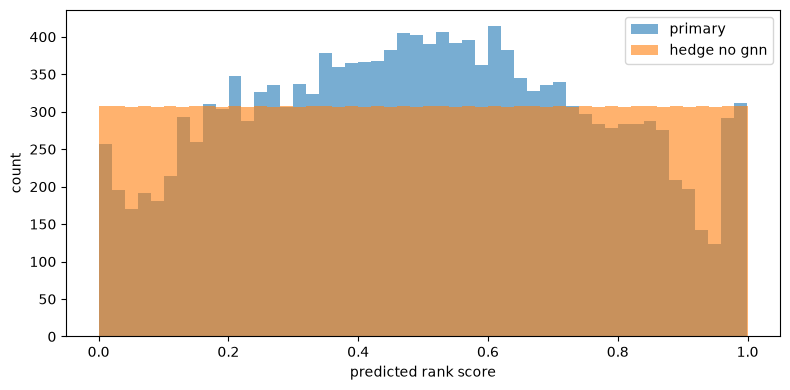

In [ ]:
# Sanity check of the primary submission: mean predicted rank per test step, and score
# histograms of both submissions
chk = pd.DataFrame({"step": test[STEP].to_numpy(), "primary": primary_pred})
print(chk.groupby("step").agg(n=("primary", "size"),
							  primary_mean=("primary", "mean")).round(4).to_string())

_, ax = plt.subplots(figsize=(8, 4))
ax.hist(primary_pred, bins=50, alpha=0.6, label="primary")
ax.hist(second_pred, bins=50, alpha=0.6, label="hedge no gnn")
ax.set_xlabel("predicted rank score")
ax.set_ylabel("count")
ax.legend()
plt.tight_layout()
plt.show()

## 14. Evaluation report

In [ ]:
# Threshold metrics on a local window: LightGBM alone,
# trained on steps 1-20 and scored on steps 21-34 (the longest tune fold). Thresholds
# are score quantiles, i.e. flagging the top 20%, 12%, 8%, 5% and 2% of transactions
EVAL_CUT, EVAL_LO, EVAL_HI = max(FOLDS, key=lambda fd: fd[2] - fd[1])
ev_va = lab[lab[STEP].between(EVAL_LO, EVAL_HI)]
p_ev = seed_bag(lgb_member, CONFIRM_SEEDS)(lab[lab[STEP] <= EVAL_CUT], ev_va, MODEL_FEATS)
y_ev = ev_va[TARGET].to_numpy()

rows = []
for t in np.quantile(p_ev, EVAL_QUANTILES):
    pred = (p_ev >= t).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y_ev, pred, average="binary", zero_division=0)
    rows.append({"threshold": round(float(t), 4), "flagged": int(pred.sum()),
		     "precision": pr, "recall": rc, "f1": f1,
		     "accuracy": float((pred == y_ev).mean())})

print(f"evaluation window: train to {EVAL_CUT}, validate {EVAL_LO}-{EVAL_HI}")
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nROC AUC {roc_auc_score(y_ev, p_ev):.4f}   "
	f"PR AUC {average_precision_score(y_ev, p_ev):.4f}   "
	f"positive rate {y_ev.mean():.4f}")

# Confusion matrix at the threshold with the best F1
best_t = max(rows, key=lambda r: r["f1"])["threshold"]
print(f"\nconfusion matrix at f1-optimal threshold {best_t}")
print(confusion_matrix(y_ev, (p_ev >= best_t).astype(int)))

evaluation window: train to 20, validate 21-34
 threshold  flagged  precision  recall     f1  accuracy
    0.7986     2201     0.5706  0.7428 0.6454    0.8746
    0.8799     1321     0.9001  0.7031 0.7895    0.9424
    0.9205      881     0.9977  0.5198 0.6835    0.9260
    0.9496      551     0.9982  0.3253 0.4906    0.8962
    0.9802      221     1.0000  0.1307 0.2312    0.8664

ROC AUC 0.8911   PR AUC 0.8005   positive rate 0.1537

confusion matrix at f1-optimal threshold 0.8799
[[9182  132]
 [ 502 1189]]


 step    n  pos    auc     ap
   21  641  100 0.9948 0.9846
   22 1763  158 0.9987 0.9901
   23 1187   53 0.9553 0.7799
   24 1126  137 0.7652 0.4902
   25  594  118 0.9995 0.9979
   26  517   96 0.9293 0.8754
   27  206   24 0.9984 0.9906
   28  284   85 1.0000 1.0000
   29 1174  329 0.7324 0.6357
   30  524   83 0.9904 0.9622
   31  710  106 0.7527 0.5721
   32 1323  342 0.7849 0.7894
   33  441   23 0.9912 0.9212
   34  515   37 0.9994 0.9919


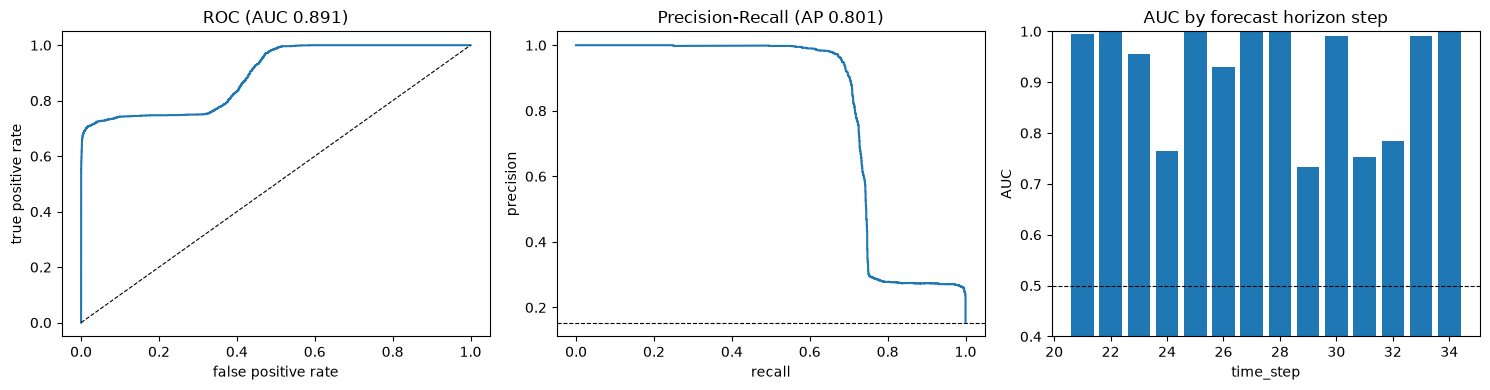

In [ ]:
# Per-step AUC and average precision on the same window, with ROC and precision-recall
# curves. A few steps (24, 29, 31 and 32) hold most of the missed illicit transactions
steps_ev = ev_va[STEP].to_numpy()
per_rows = []
for s in np.unique(steps_ev):
	mm = steps_ev == s
	two_class = len(np.unique(y_ev[mm])) > 1
	per_rows.append({"step": int(s), "n": int(mm.sum()), "pos": int(y_ev[mm].sum()),
					 "auc": roc_auc_score(y_ev[mm], p_ev[mm]) if two_class else np.nan,
					 "ap": average_precision_score(y_ev[mm], p_ev[mm]) if two_class else np.nan})
per = pd.DataFrame(per_rows)
print(per.round(4).to_string(index=False))

_, ax = plt.subplots(1, 3, figsize=(15, 4))

fpr, tpr, _ = roc_curve(y_ev, p_ev)
ax[0].plot(fpr, tpr)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_title(f"ROC (AUC {roc_auc_score(y_ev, p_ev):.3f})")
ax[0].set_xlabel("false positive rate")
ax[0].set_ylabel("true positive rate")

prc, rcc, _ = precision_recall_curve(y_ev, p_ev)
ax[1].plot(rcc, prc)
ax[1].axhline(y_ev.mean(), color="k", ls="--", lw=0.8)
ax[1].set_title(f"Precision-Recall (AP {average_precision_score(y_ev, p_ev):.3f})")
ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision")

ax[2].bar(per["step"].to_numpy(), per["auc"].to_numpy())
ax[2].axhline(0.5, color="k", ls="--", lw=0.8)
ax[2].set_ylim(0.4, 1.0)
ax[2].set_title("AUC by forecast horizon step")
ax[2].set_xlabel("time_step")
ax[2].set_ylabel("AUC")

plt.tight_layout()
plt.show()

In [ ]:
# comparison table plus key settings and scores, saved as run_summary_<tag>.json next to the submissions
summary = pd.DataFrame(results).sort_values("tune", ascending=False)
print(summary.round(4).to_string(index=False))

final_row = {
	"n_features": len(MODEL_FEATS),
	"run_tag": RUN_TAG,
	"noise_se": round(NOISE_SE, 4),
	"base_trees": BASE_TREES,
	"final_tree_scale": round(FINAL_SCALE, 3),
	"half_life": BEST_HL,
	"gnn_weight": GNN_WEIGHT,
	"gnn_epochs": GNN_EPOCHS,
    "gnn_seeds": len(GNN_SEEDS),
	"gnn_hidden": GNN_HIDDEN,
    "lgb_seeds": len(FINAL_SEEDS),
    "graph_block": spec["graph_block_selected"],
	"lgb_cv": round(LGB_CV, 4),
    "lgb_select": round(LGB_SELECT, 4),
    "shipped_trees": BEST_CFG["n_estimators"],
	"adversarial_auc_final": round(spec["adversarial_auc_final"], 4),
	"eval_window": f"{EVAL_LO}-{EVAL_HI}",
	"eval_auc": round(roc_auc_score(y_ev, p_ev), 4),
	"eval_ap": round(average_precision_score(y_ev, p_ev), 4),
}
print(f"\n{json.dumps(final_row, indent=2)}")
(SUBMISSION_DIR / f"run_summary_{RUN_TAG}.json").write_text(
	json.dumps(final_row, indent=2, default=str))

                 model   tune  select  worst    std
    lgb / is_unbalance 0.9483  0.9469 0.8628 0.0515
lgb / scale_pos_weight 0.9444  0.9415 0.8553 0.0553
       lgb / no weight 0.9415  0.9382 0.8533 0.0541
       xgb / no weight 0.9380  0.9318 0.8081 0.0636
xgb / scale_pos_weight 0.9336  0.9279 0.8055 0.0662
              catboost 0.9294  0.9277 0.7934 0.0749
           extra trees 0.9222  0.9123 0.7988 0.0786
         random forest 0.9136  0.9027 0.7656 0.0856
                logreg 0.8815  0.8803 0.8041 0.0422

{
  "n_features": 162,
  "run_tag": "20261024_2154",
  "noise_se": 0.0018,
  "base_trees": 348,
  "final_tree_scale": 1.05,
  "half_life": 5,
  "gnn_weight": 0.4,
  "gnn_epochs": 739,
  "gnn_seeds": 20,
  "gnn_hidden": 64,
  "lgb_seeds": 20,
  "graph_block": "base",
  "lgb_cv": 0.957,
  "lgb_select": 0.9487,
  "shipped_trees": 219,
  "adversarial_auc_final": 1.0,
  "eval_window": "21-34",
  "eval_auc": 0.8911,
  "eval_ap": 0.8005
}


435

## 15. Report figures

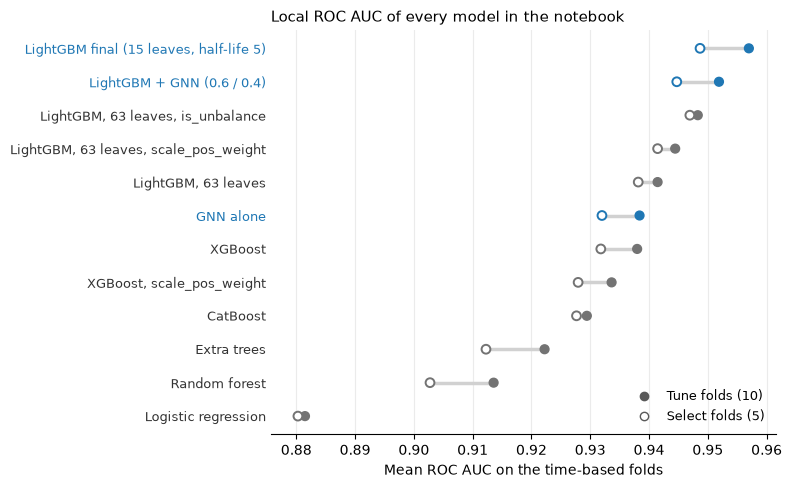

                                  model   tune  select  final
                    Logistic regression 0.8815  0.8803  False
                          Random forest 0.9136  0.9027  False
                            Extra trees 0.9222  0.9123  False
                               CatBoost 0.9294  0.9277  False
              XGBoost, scale_pos_weight 0.9336  0.9279  False
                                XGBoost 0.9380  0.9318  False
                              GNN alone 0.9384  0.9320   True
                    LightGBM, 63 leaves 0.9415  0.9382  False
  LightGBM, 63 leaves, scale_pos_weight 0.9444  0.9415  False
      LightGBM, 63 leaves, is_unbalance 0.9483  0.9469  False
             LightGBM + GNN (0.6 / 0.4) 0.9519  0.9447   True
LightGBM final (15 leaves, half-life 5) 0.9570  0.9487   True
saved c:\Users\iiank-laptop\OneDrive\Documents\NUS\Y3\Y3S1\BT4012\Kaggle\figures\figure1_model_comparison.png


In [ ]:
# Figure 1 of the report: mean ROC AUC of every model this notebook evaluated, on the tune
# folds (filled) and the select folds (open)
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Display names for the comparison models stored in results (sections 7 and 8)
NAMES = {"logreg": "Logistic regression", "random forest": "Random forest",
         "extra trees": "Extra trees", "catboost": "CatBoost",
         "xgb / no weight": "XGBoost", "xgb / scale_pos_weight": "XGBoost, scale_pos_weight",
         "lgb / no weight": "LightGBM, 63 leaves",
         "lgb / scale_pos_weight": "LightGBM, 63 leaves, scale_pos_weight",
         "lgb / is_unbalance": "LightGBM, 63 leaves, is_unbalance"}
others = pd.DataFrame(results)[["model", "tune", "select"]].assign(final=False)
others["model"] = others["model"].map(lambda m: NAMES.get(m, m))

# The final LightGBM, the GNN and their blend, scored on the same folds (sections 11 and 12)
final = pd.DataFrame([
    {"model": "LightGBM final (15 leaves, half-life 5)", "tune": LGB_CV, "select": LGB_SELECT},
    {"model": "GNN alone", "tune": mix(1.0, oof_cv, g_cv, y_cv).mean(),
     "select": mix(1.0, oof_ho, g_ho, y_ho).mean()},
    {"model": f"LightGBM + GNN ({1 - GNN_WEIGHT:.1f} / {GNN_WEIGHT:.1f})",
     "tune": mix(GNN_WEIGHT, oof_cv, g_cv, y_cv).mean(),
     "select": mix(GNN_WEIGHT, oof_ho, g_ho, y_ho).mean()},
]).assign(final=True)

fig_df = pd.concat([others, final], ignore_index=True).sort_values("tune").reset_index(drop=True)
fig_df.round(4).to_csv(FIG_DIR / "figure1_model_comparison.csv", index=False)

yy = np.arange(len(fig_df))
col = np.where(fig_df["final"], "tab:blue", "0.45")
fig, ax = plt.subplots(figsize=(8, 0.34 * len(fig_df) + 0.9))

ax.hlines(yy, fig_df["select"], fig_df["tune"], color="0.82", lw=2.5, zorder=1)
ax.scatter(fig_df["tune"], yy, c=col, s=40, zorder=3)
ax.scatter(fig_df["select"], yy, facecolors="white", edgecolors=col, s=40, linewidths=1.4, zorder=3)
ax.set_yticks(yy)
ax.set_yticklabels(fig_df["model"], fontsize=9)
for label, is_final in zip(ax.get_yticklabels(), fig_df["final"]):
    label.set_color("tab:blue" if is_final else "0.2")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color="0.35", label=f"Tune folds ({len(FOLDS)})"),
                   plt.Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="0.35",
                              label=f"Select folds ({len(FOLDS_SELECT)})")],
          loc="lower right", frameon=False, fontsize=9)
ax.set_xlabel("Mean ROC AUC on the time-based folds")
ax.margins(x=0.06)
ax.grid(axis="x", color="0.92", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.set_title("Local ROC AUC of every model in the notebook", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure1_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print(fig_df.round(4).to_string(index=False))
print(f"saved {FIG_DIR / 'figure1_model_comparison.png'}")